# Dataset C: COVID-19 Vaccine Uptake Prediction

This notebook explores Dataset C, preprocesses the predictors, compares classification
models, evaluates performance, explains model behaviour, and generates test-set predictions.

**Important:** cost values added in the cost-analysis sections are editable scenario assumptions.
They are not present in the supplied CSV files and must be justified before being reported
as real-world estimates.

In [ ]:

# Data manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

# Evaluation
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    log_loss
)

# Settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42


In [ ]:
train = pd.read_csv("/content/dataset_C_training.csv")
test = pd.read_csv("/content/dataset_C_testing.csv")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

display(train.head())
display(test.head())


Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


## Added: Data integrity checks

Run this after loading the training and testing CSV files. It checks the target, identifiers,
duplicate rows, and whether the training and test feature columns match. It does not modify
the original datasets.

In [ ]:
TARGET = "covid_vaccine"
ID_COL = "respondent_id"

assert TARGET in train.columns, f"Missing target column: {TARGET}"
assert ID_COL in train.columns and ID_COL in test.columns, f"Missing ID column: {ID_COL}"
assert train[TARGET].notna().all(), "The training target contains missing values."
assert set(train[TARGET].dropna().unique()).issubset({0, 1}), (
    "Expected covid_vaccine to contain binary labels 0 and 1."
)

train_features = set(train.columns) - {TARGET, ID_COL}
test_features = set(test.columns) - {ID_COL}
print("Training rows duplicated:", train.duplicated().sum())
print("Training IDs duplicated:", train[ID_COL].duplicated().sum())
print("Testing IDs duplicated:", test[ID_COL].duplicated().sum())
print("Features missing from test:", sorted(train_features - test_features))
print("Extra features in test:", sorted(test_features - train_features))

assert train_features == test_features, (
    "Training and testing feature columns differ. Resolve this before modelling."
)
assert train[ID_COL].is_unique, "Training respondent_id values are not unique."
assert test[ID_COL].is_unique, "Testing respondent_id values are not unique."

print("\nTarget distribution:")
display(train[TARGET].value_counts(normalize=True).rename("proportion").to_frame())

Training rows duplicated: 0
Training IDs duplicated: 0
Testing IDs duplicated: 0
Features missing from test: []
Extra features in test: []

Target distribution:


,proportion
covid_vaccine,
0,0.673255
1,0.326745


In [ ]:

# Dataset information
train.info()

# Statistical summary
display(train.describe().T)

# Summary including categorical features
display(train.describe(include="all").T)

# Column names
print(train.columns.tolist())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance               2848 non-null   f

,count,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,2378.500000,1373.083270,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,1.648609,0.903204,0.0,1.00,2.0,2.00,3.0
covid_knowledge,4729.0,1.296469,0.615705,0.0,1.00,1.0,2.00,2.0
behavioral_antiviral_meds,4742.0,0.053353,0.224760,0.0,0.00,0.0,0.00,1.0
behavioral_avoidance,4729.0,0.733347,0.442256,0.0,0.00,1.0,1.00,1.0
behavioral_face_mask,4754.0,0.072991,0.260149,0.0,0.00,0.0,0.00,1.0
behavioral_wash_hands,4747.0,0.839267,0.367323,0.0,1.00,1.0,1.00,1.0
behavioral_large_gatherings,4746.0,0.356300,0.478956,0.0,0.00,0.0,1.00,1.0
behavioral_outside_home,4742.0,0.329186,0.469967,0.0,0.00,0.0,1.00,1.0
behavioral_touch_face,4735.0,0.693981,0.460886,0.0,0.00,1.0,1.00,1.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0


['respondent_id', 'covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'employment_sector', 'number_chronic_med_conditions', 'covid_vaccine']


Target counts:


,count
covid_vaccine,
0,3202
1,1554


Target percentages:


,proportion
covid_vaccine,
0,67.33
1,32.67


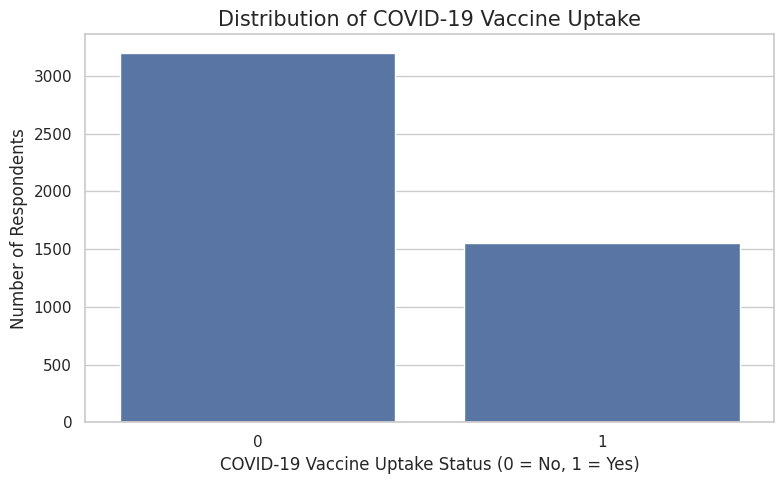

In [ ]:

target_counts = train["covid_vaccine"].value_counts().sort_index()

target_percentages = (
    train["covid_vaccine"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Target counts:")
display(target_counts)

print("Target percentages:")
display(target_percentages.round(2))

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train,
    x="covid_vaccine"
)

plt.title(
    "Distribution of COVID-19 Vaccine Uptake",
    fontsize=15
)

plt.xlabel(
    "COVID-19 Vaccine Uptake Status (0 = No, 1 = Yes)"
)

plt.ylabel(
    "Number of Respondents"
)

plt.tight_layout()
plt.show()


,Feature,Missing Values,Missing Percentage
28,employment_sector,2330,48.990749
12,health_insurance,1908,40.117746
17,income_poverty,748,15.727502
19,rent_or_own,329,6.917578
20,employment_status,238,5.004205
18,marital_status,231,4.857023
14,education,228,4.793944
10,child_under_6_months,135,2.838520
11,health_worker,132,2.775442
27,opinion_covid_sick_from_vacc,90,1.892347


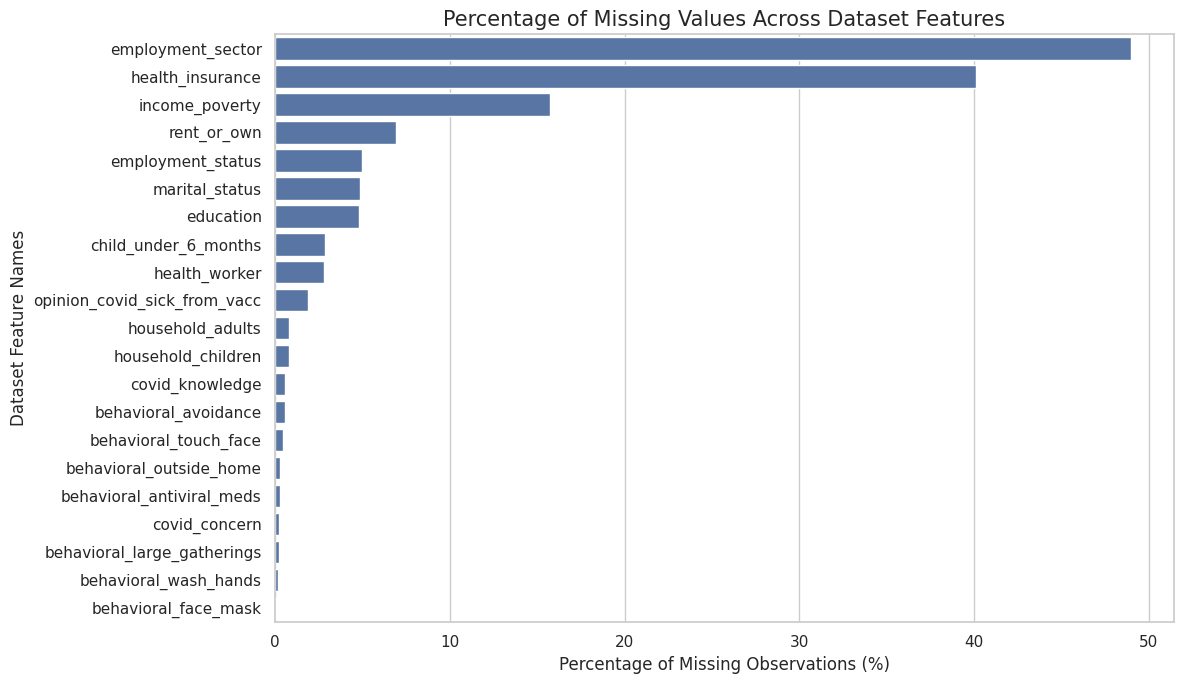

In [ ]:

missing = pd.DataFrame({
    "Feature": train.columns,
    "Missing Values": train.isnull().sum().values,
    "Missing Percentage": (
        train.isnull().mean().values * 100
    )
})

missing = missing.sort_values(
    "Missing Percentage",
    ascending=False
)

missing = missing[missing["Missing Values"] > 0]

display(missing)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing,
    x="Missing Percentage",
    y="Feature"
)

plt.title(
    "Percentage of Missing Values Across Dataset Features",
    fontsize=15
)

plt.xlabel(
    "Percentage of Missing Observations (%)"
)

plt.ylabel(
    "Dataset Feature Names"
)

plt.tight_layout()
plt.show()


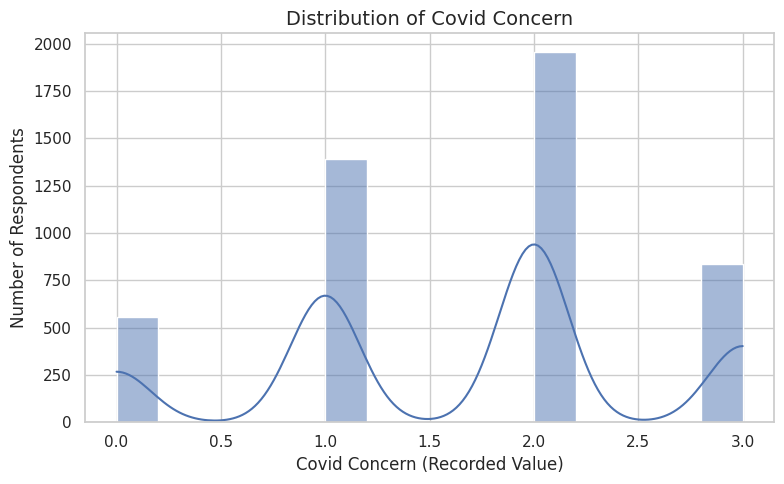

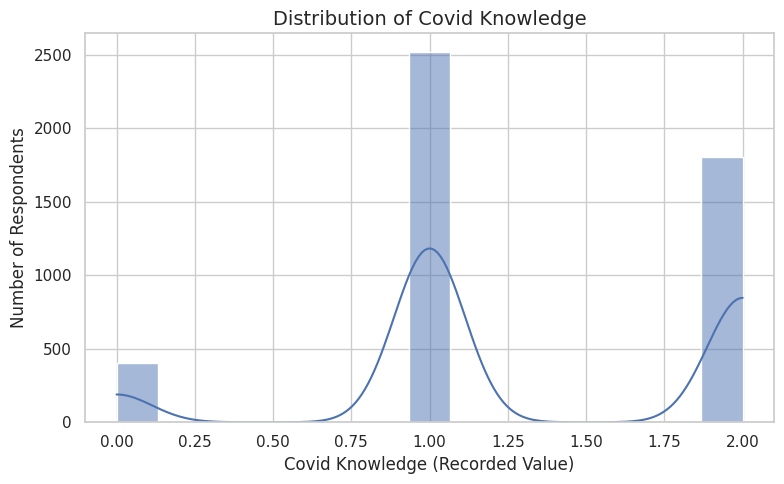

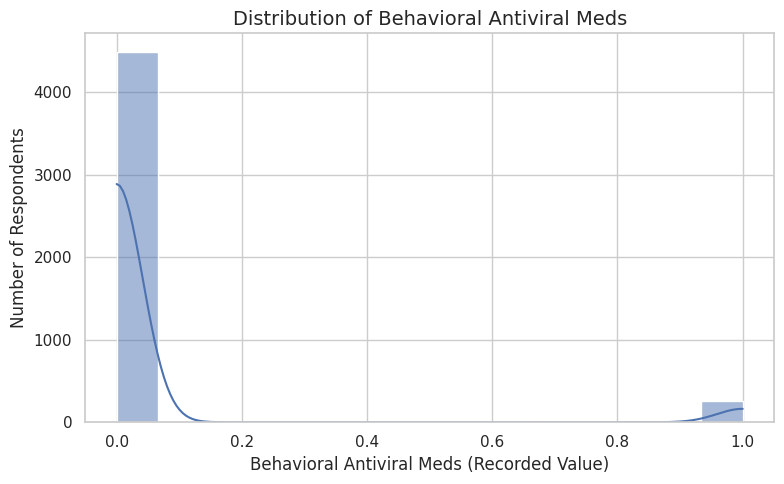

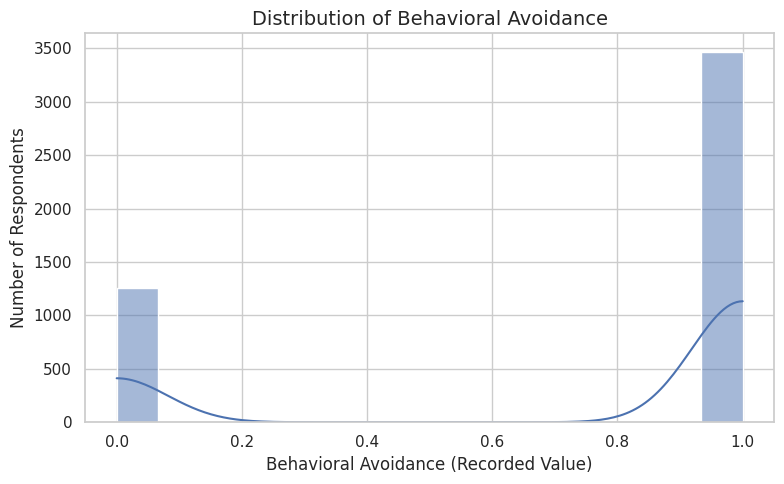

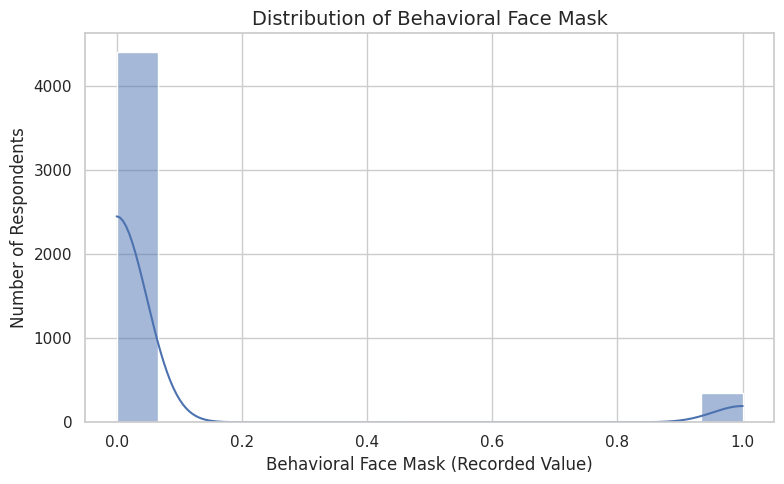

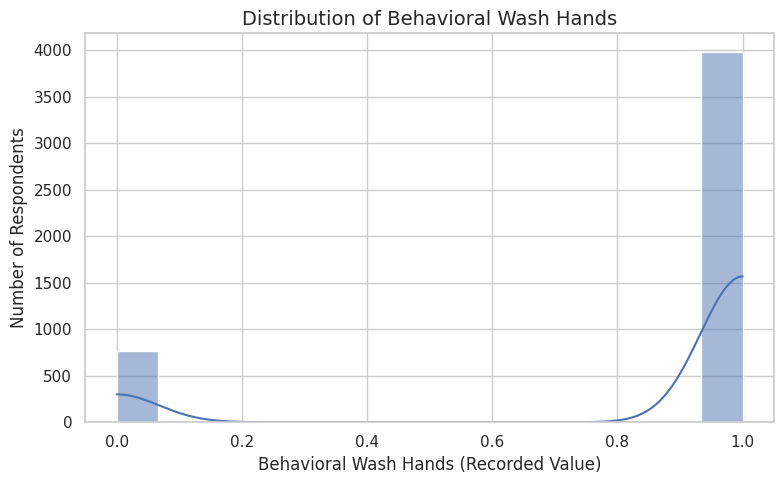

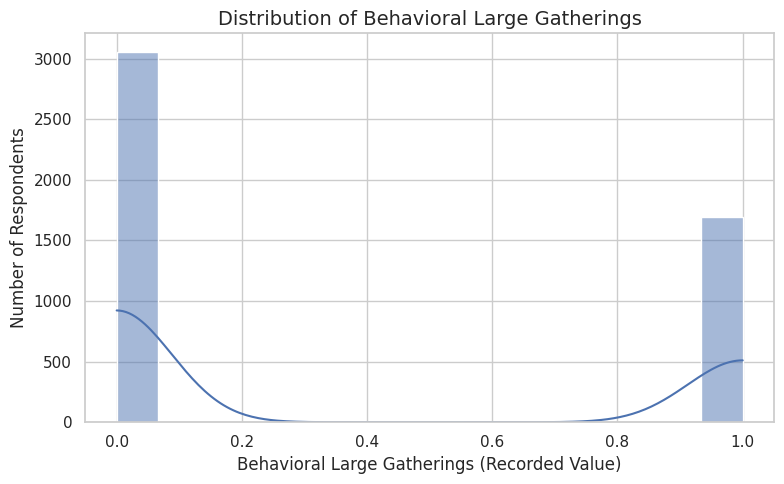

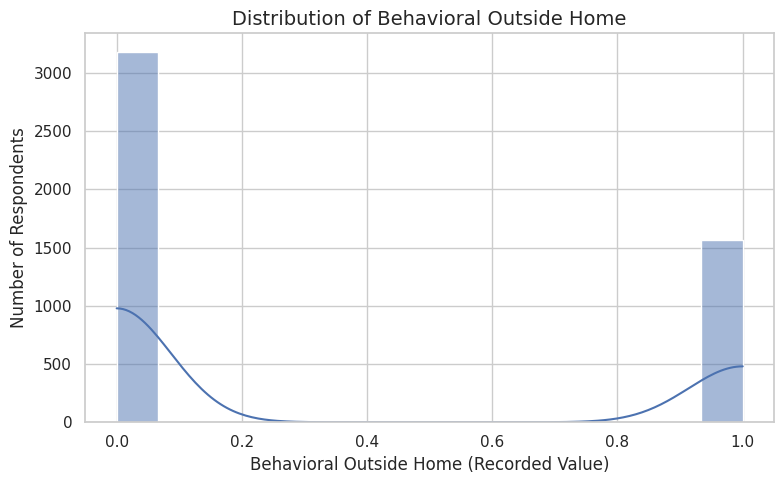

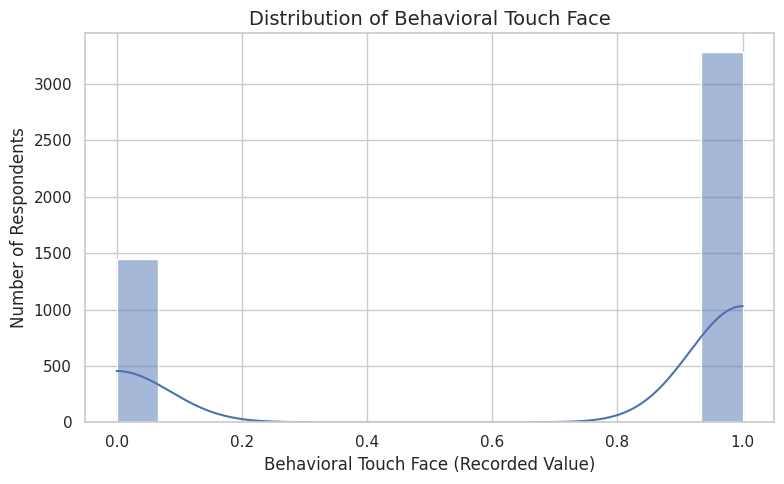

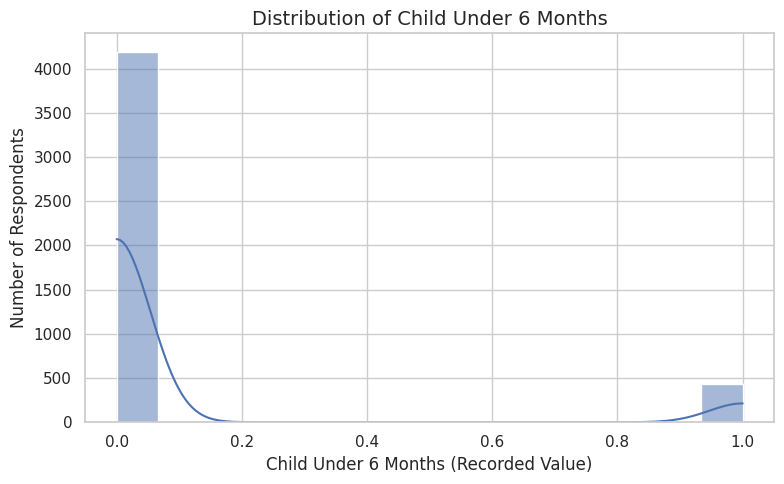

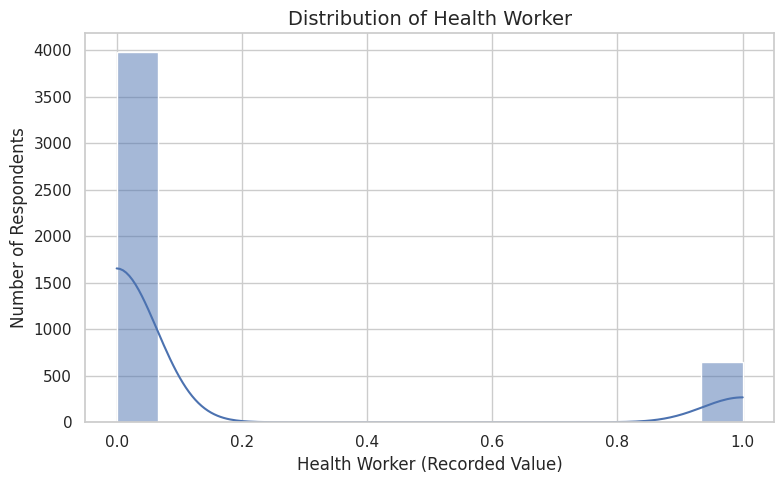

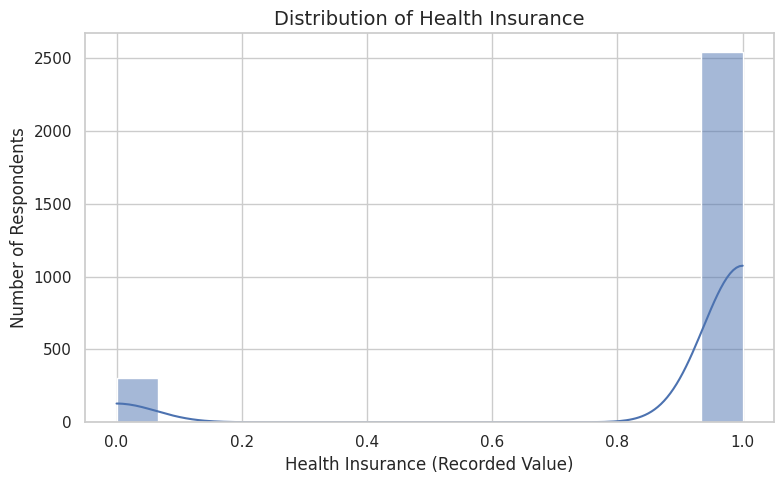

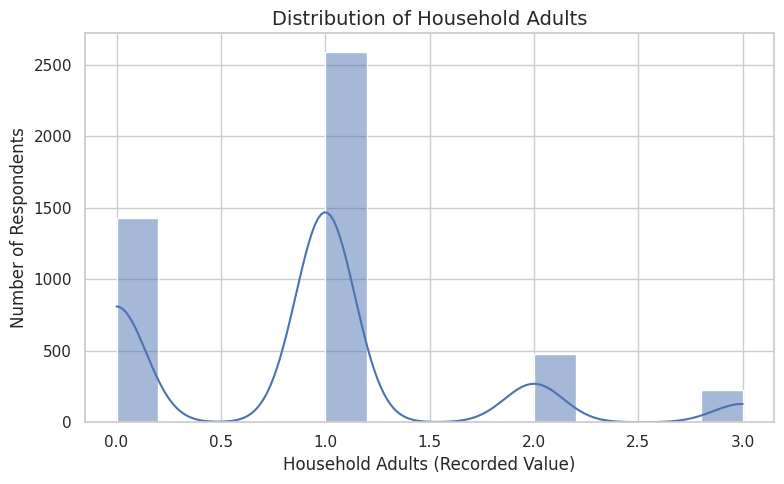

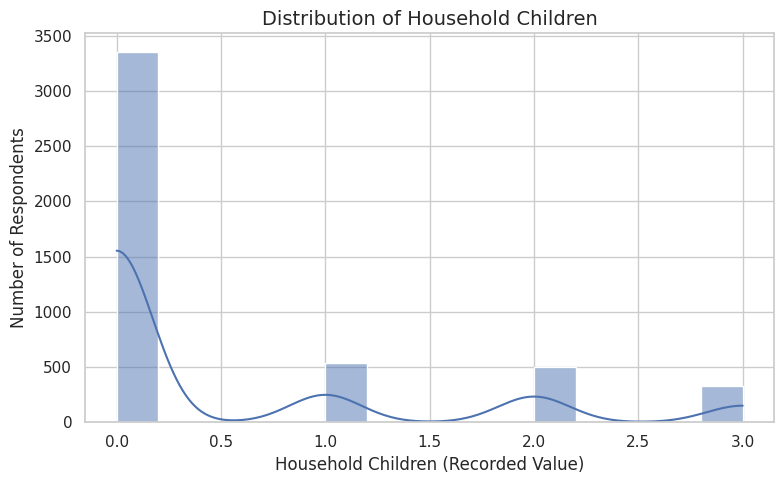

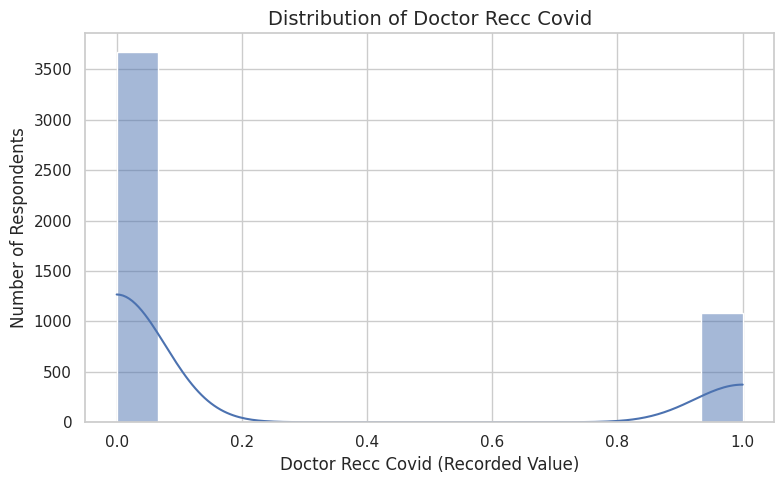

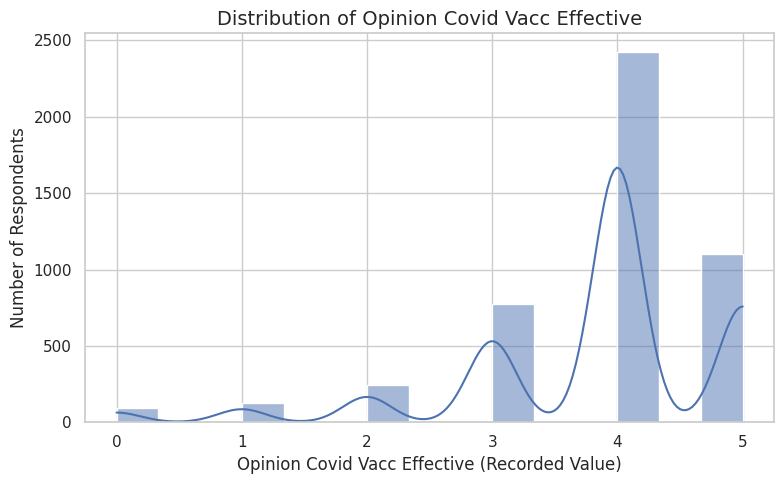

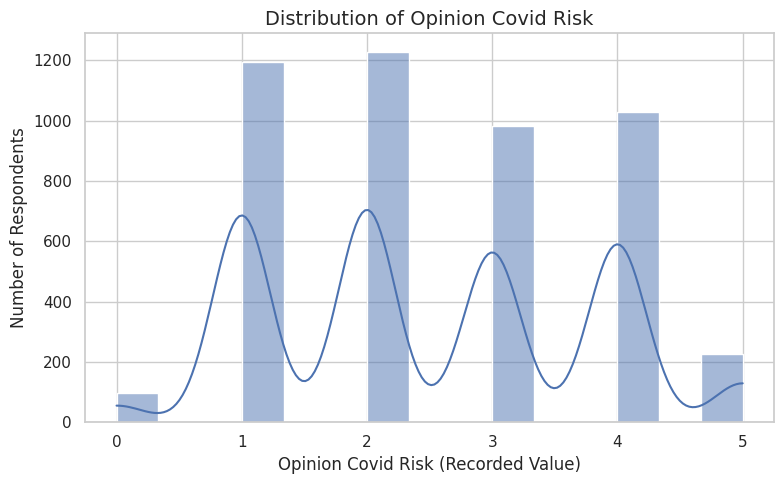

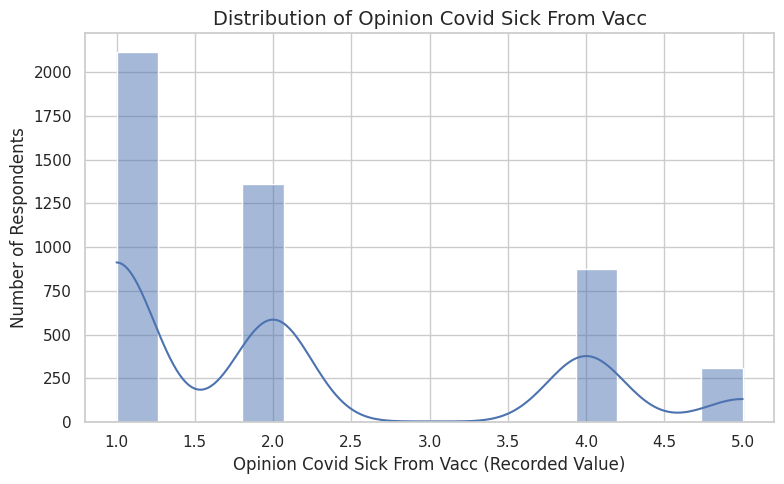

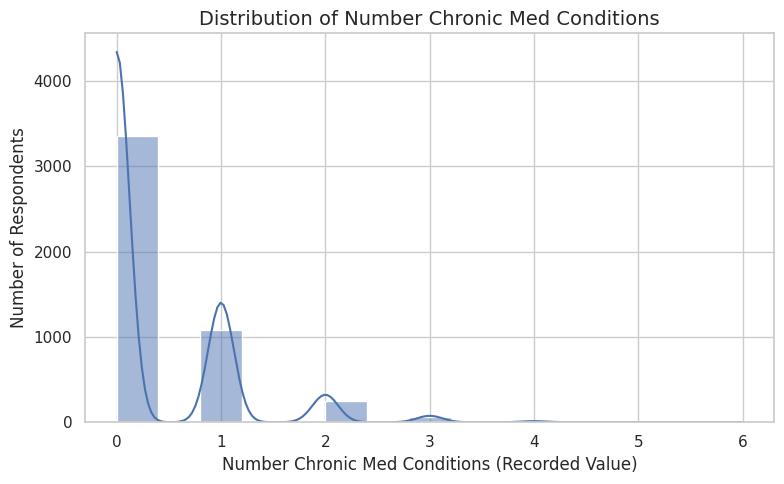

In [ ]:

numeric_features = train.select_dtypes(
    include=np.number
).columns.tolist()

numeric_features = [
    col for col in numeric_features
    if col not in ["respondent_id", "covid_vaccine"]
]

for col in numeric_features:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=train,
        x=col,
        kde=True,
        bins=15
    )

    plt.title(
        f"Distribution of {col.replace('_', ' ').title()}",
        fontsize=14
    )

    plt.xlabel(
        f"{col.replace('_', ' ').title()} (Recorded Value)"
    )

    plt.ylabel(
        "Number of Respondents"
    )

    plt.tight_layout()
    plt.show()


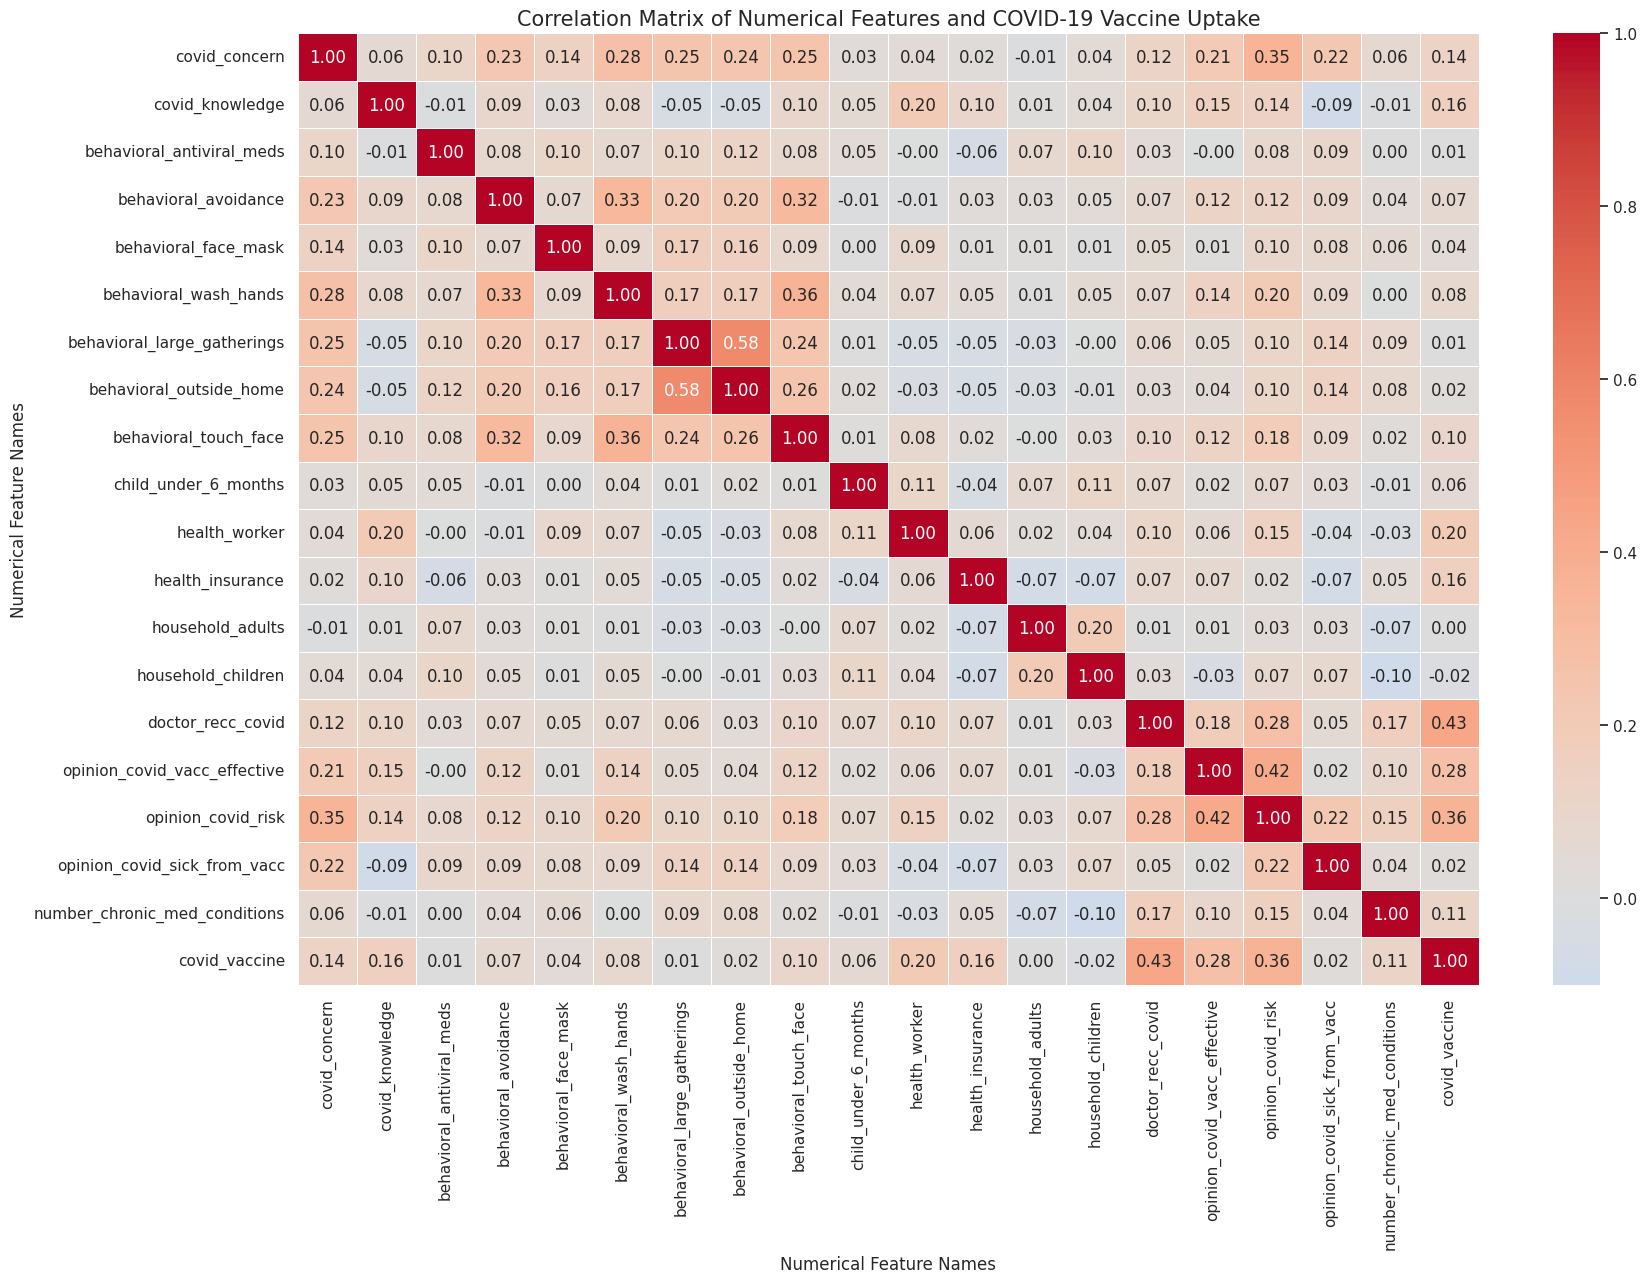

In [ ]:

correlation_data = train.select_dtypes(
    include=np.number
).drop(
    columns=["respondent_id"],
    errors="ignore"
)

correlation_matrix = correlation_data.corr(
    method="pearson"
)

plt.figure(figsize=(18, 13))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Numerical Features and COVID-19 Vaccine Uptake",
    fontsize=15
)

plt.xlabel(
    "Numerical Feature Names"
)

plt.ylabel(
    "Numerical Feature Names"
)

plt.tight_layout()
plt.show()


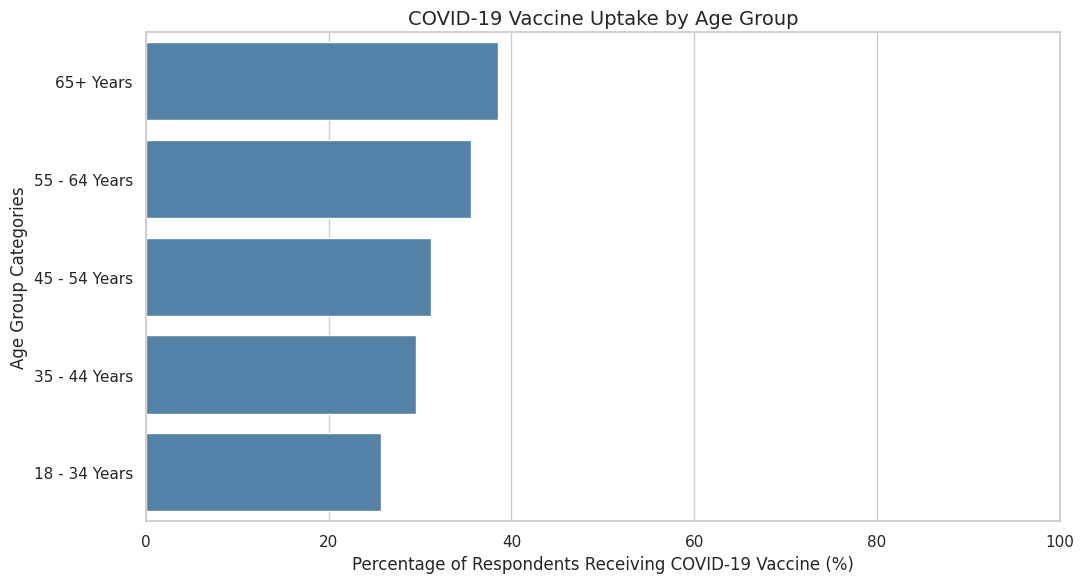

,age_group,count,mean,Uptake Percentage
4,65+ Years,1208,0.385762,38.576159
3,55 - 64 Years,992,0.355847,35.584677
2,45 - 54 Years,948,0.312236,31.223629
1,35 - 44 Years,661,0.295008,29.500756
0,18 - 34 Years,947,0.257656,25.765576


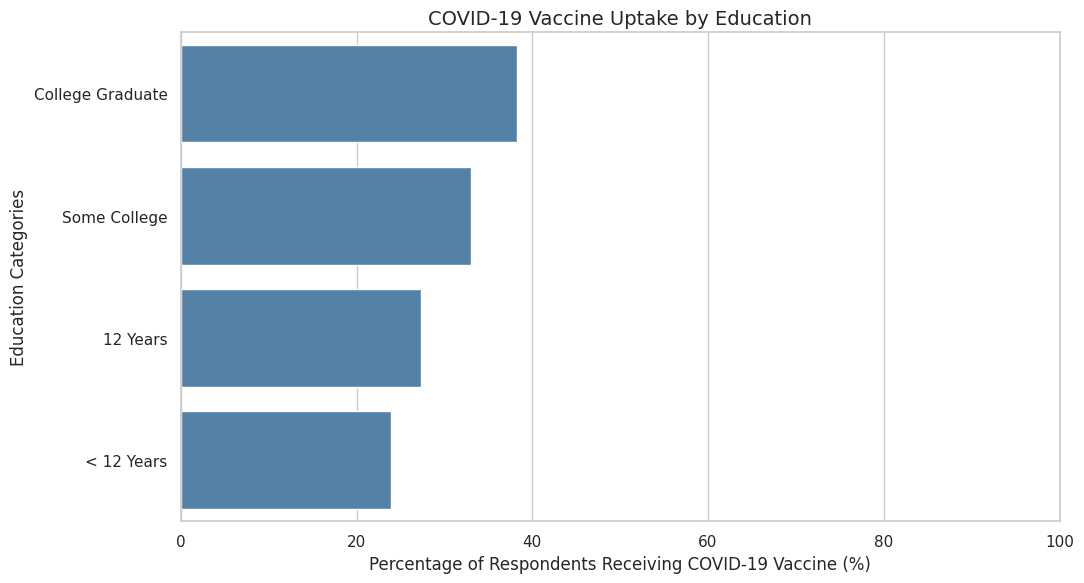

,education,count,mean,Uptake Percentage
2,College Graduate,1883,0.382900,38.289963
3,Some College,1222,0.330606,33.060556
0,12 Years,1018,0.273084,27.308448
1,< 12 Years,405,0.239506,23.950617
4,NaN,228,0.236842,23.684211


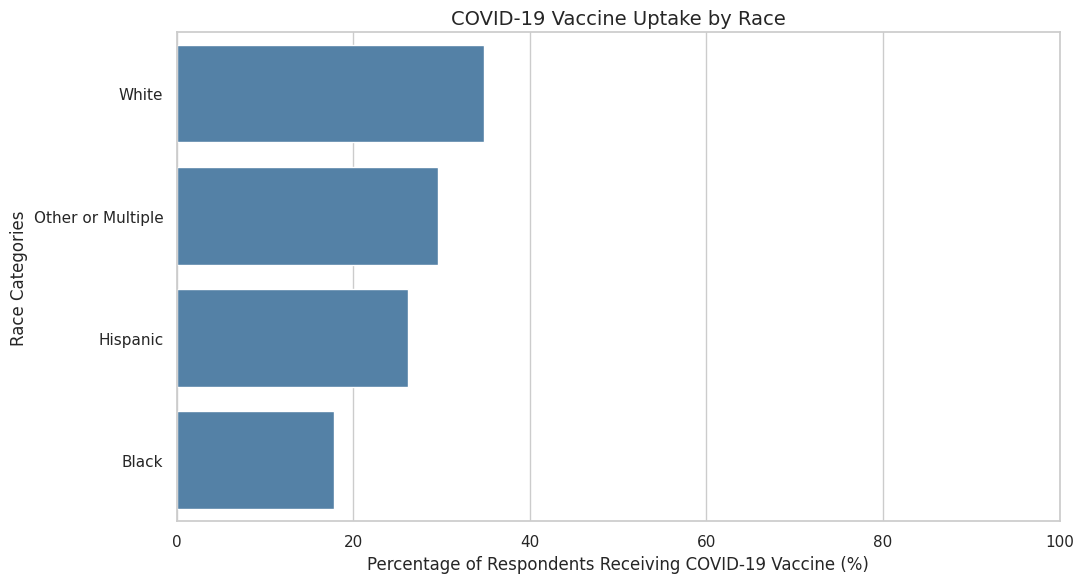

,race,count,mean,Uptake Percentage
3,White,3798,0.348341,34.834123
2,Other or Multiple,284,0.295775,29.577465
1,Hispanic,321,0.261682,26.168224
0,Black,353,0.178470,17.847025


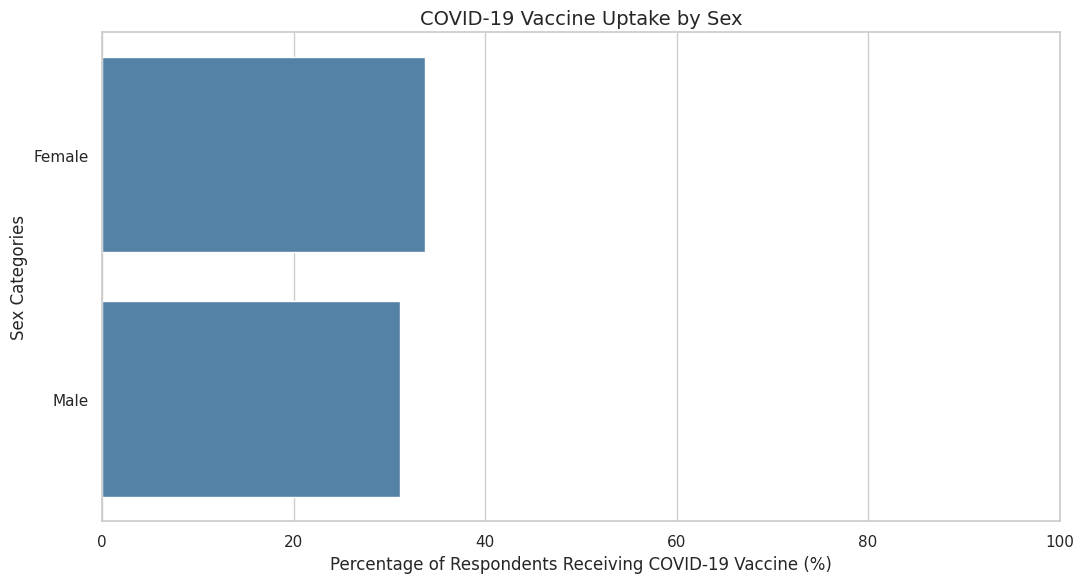

,sex,count,mean,Uptake Percentage
0,Female,2865,0.336824,33.682373
1,Male,1891,0.311475,31.147541


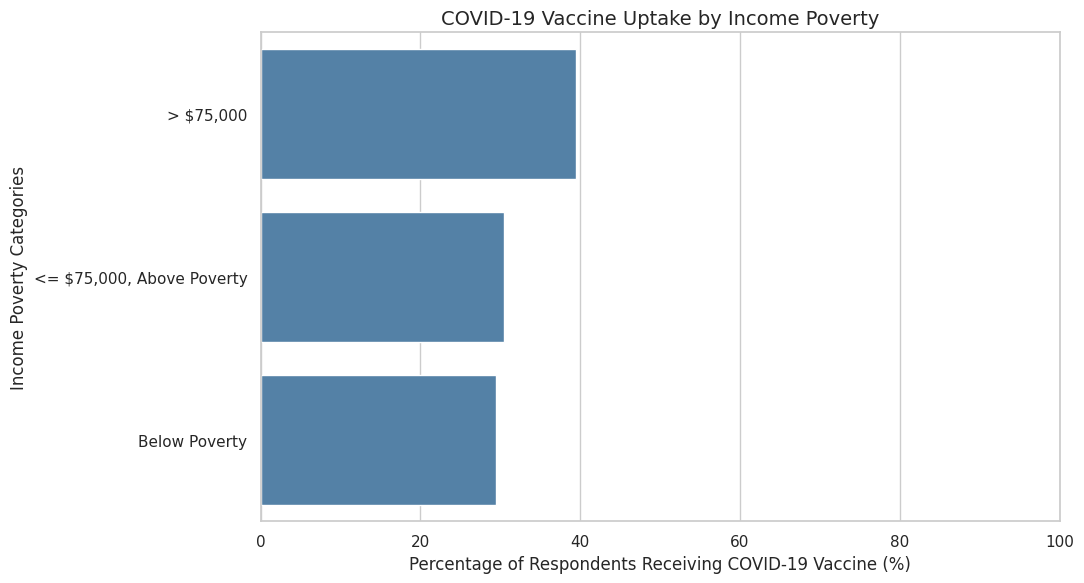

,income_poverty,count,mean,Uptake Percentage
1,"> $75,000",1295,0.395367,39.536680
0,"<= $75,000, Above Poverty",2255,0.305100,30.509978
2,Below Poverty,458,0.294760,29.475983
3,NaN,748,0.292781,29.278075


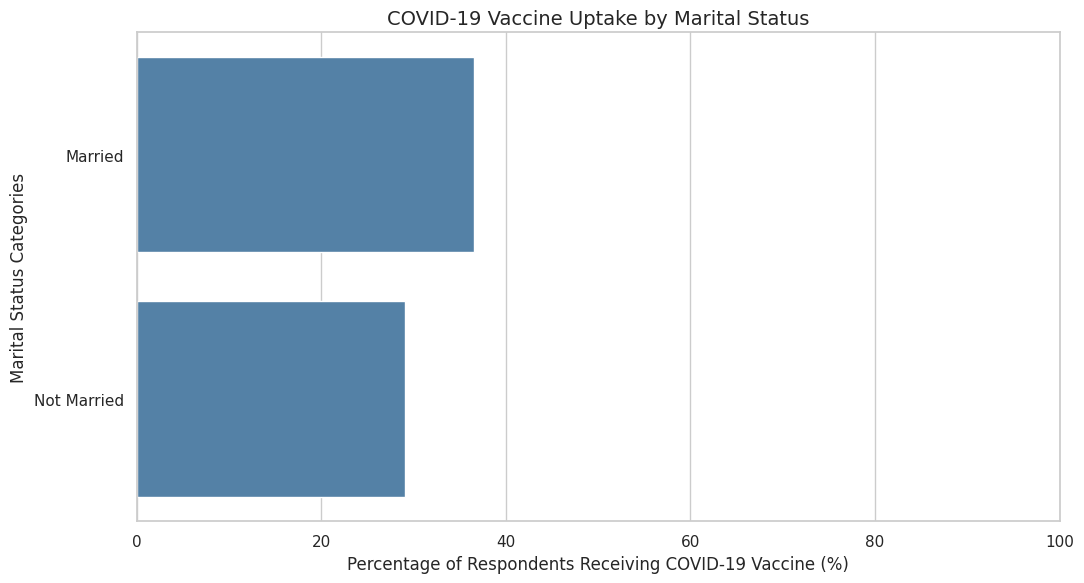

,marital_status,count,mean,Uptake Percentage
0,Married,2464,0.364854,36.485390
1,Not Married,2061,0.291121,29.112082
2,NaN,231,0.238095,23.809524


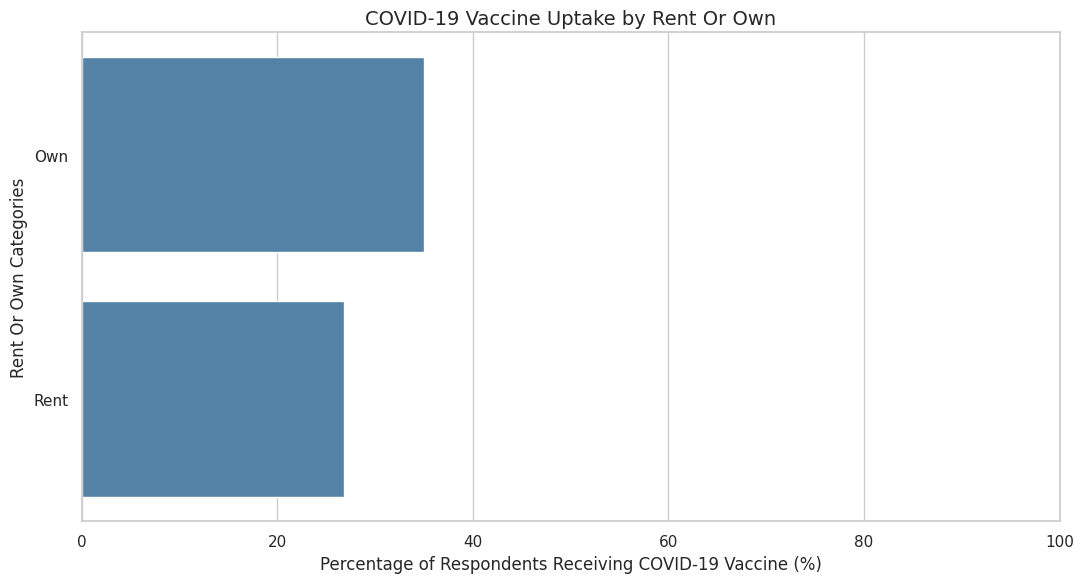

,rent_or_own,count,mean,Uptake Percentage
0,Own,3393,0.349838,34.983790
2,NaN,329,0.273556,27.355623
1,Rent,1034,0.267892,26.789168


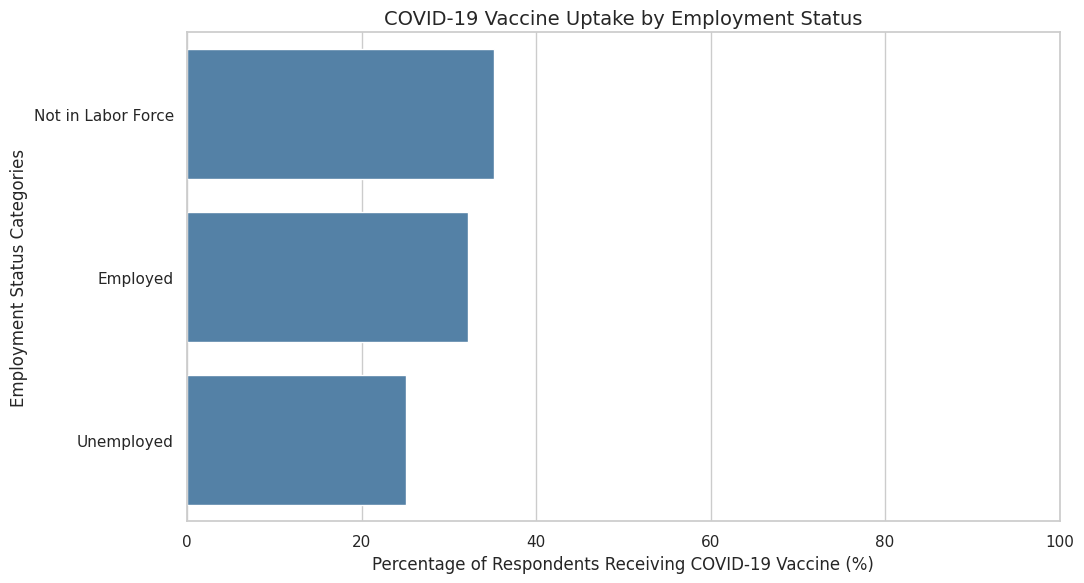

,employment_status,count,mean,Uptake Percentage
1,Not in Labor Force,1808,0.352323,35.232301
0,Employed,2451,0.322317,32.231742
3,NaN,238,0.260504,26.050420
2,Unemployed,259,0.250965,25.096525


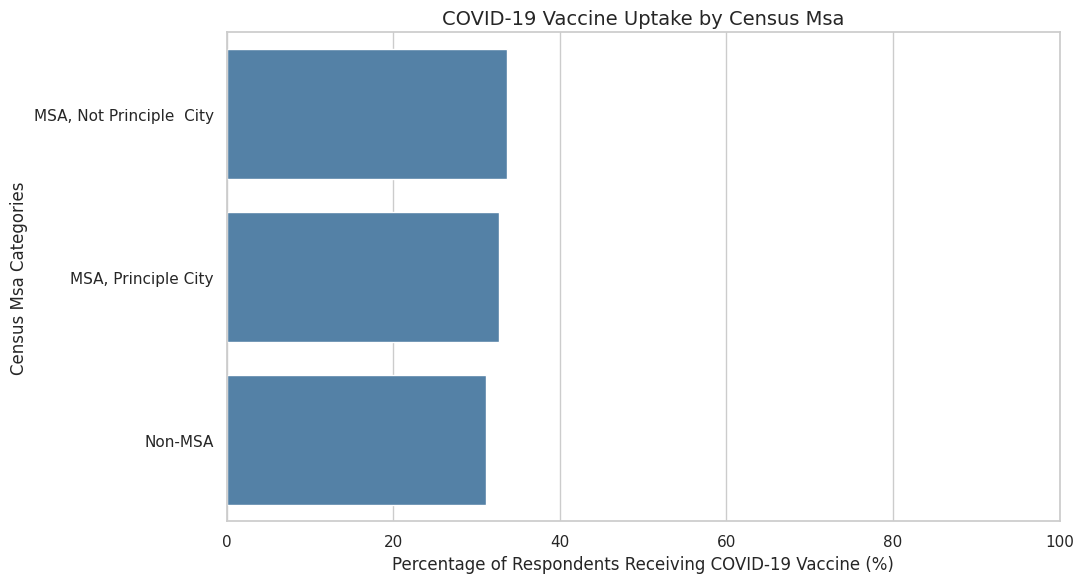

,census_msa,count,mean,Uptake Percentage
0,"MSA, Not Principle City",2104,0.336027,33.602662
1,"MSA, Principle City",1413,0.326964,32.696391
2,Non-MSA,1239,0.310734,31.073446


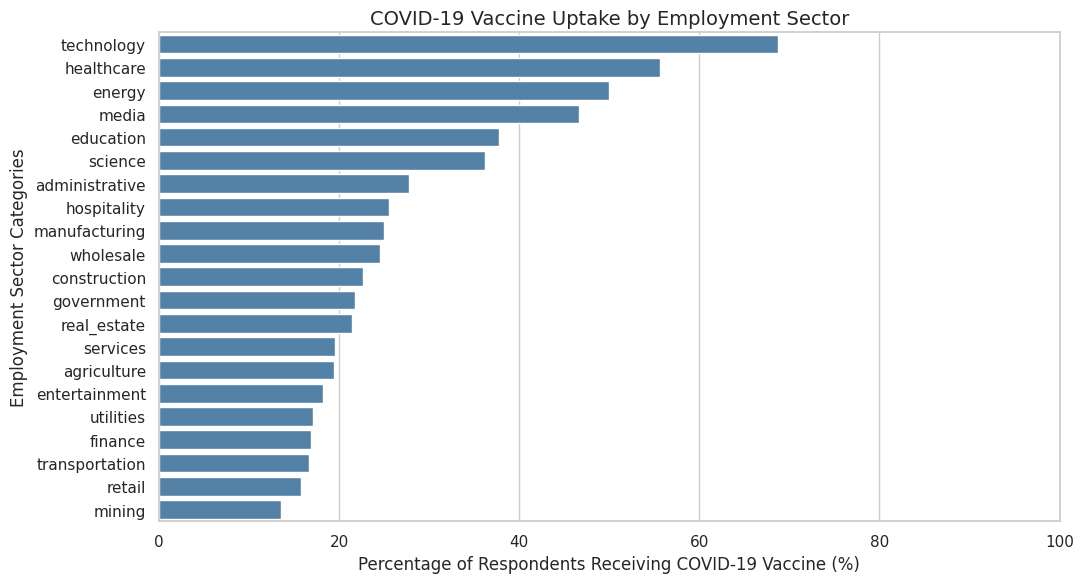

,employment_sector,count,mean,Uptake Percentage
17,technology,48,0.687500,68.750000
8,healthcare,527,0.555977,55.597723
4,energy,2,0.500000,50.000000
11,media,15,0.466667,46.666667
3,education,159,0.377358,37.735849
15,science,337,0.362018,36.201780
21,NaN,2330,0.327897,32.789700
0,administrative,18,0.277778,27.777778
9,hospitality,98,0.255102,25.510204
10,manufacturing,56,0.250000,25.000000


In [ ]:

categorical_features = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_features:

    summary = (
        train.groupby(col, dropna=False)["covid_vaccine"]
        .agg(["count", "mean"])
        .reset_index()
    )

    summary["Uptake Percentage"] = (
        summary["mean"] * 100
    )

    summary = summary.sort_values(
        "Uptake Percentage",
        ascending=False
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=summary,
        x="Uptake Percentage",
        y=col,
        color="steelblue"
    )

    plt.title(
        f"COVID-19 Vaccine Uptake by {col.replace('_', ' ').title()}",
        fontsize=14
    )

    plt.xlabel(
        "Percentage of Respondents Receiving COVID-19 Vaccine (%)"
    )

    plt.ylabel(
        col.replace("_", " ").title() + " Categories"
    )

    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

    display(summary)


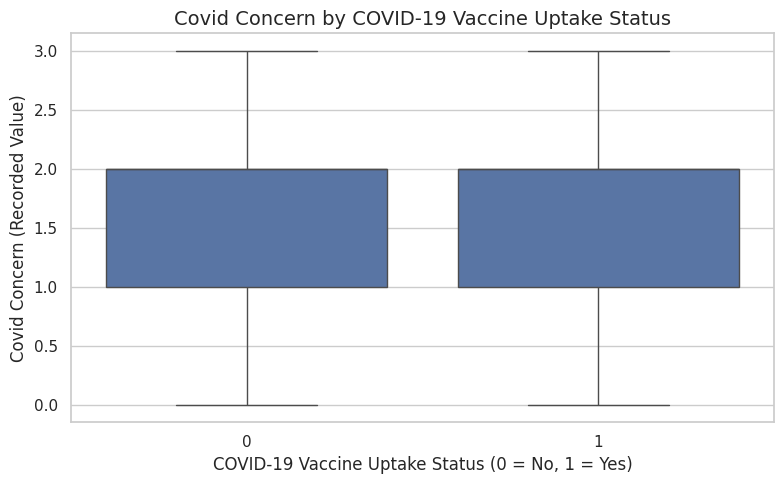

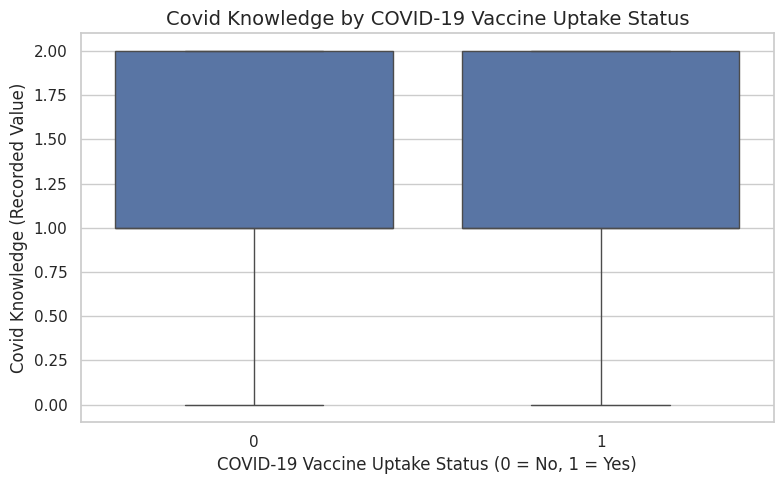

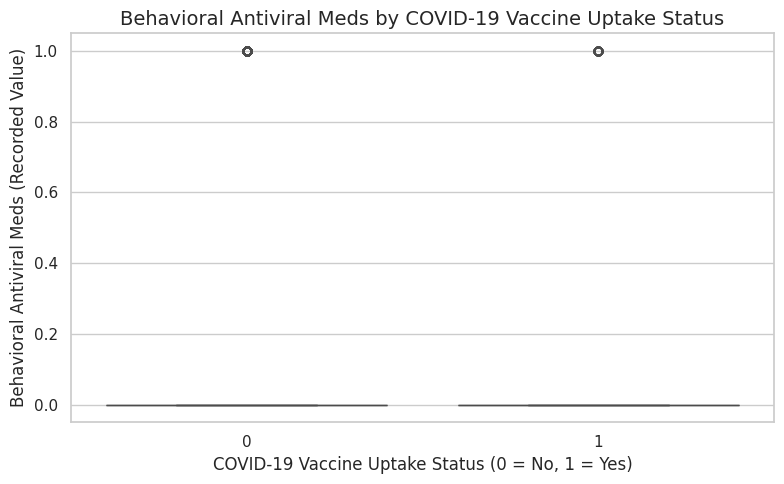

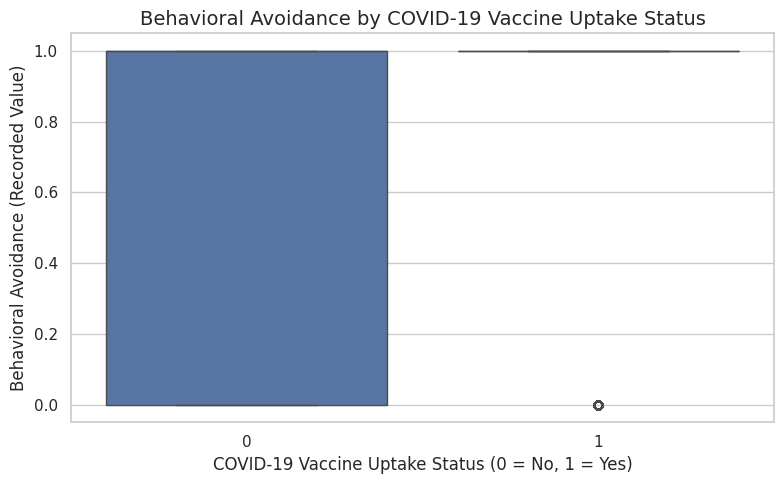

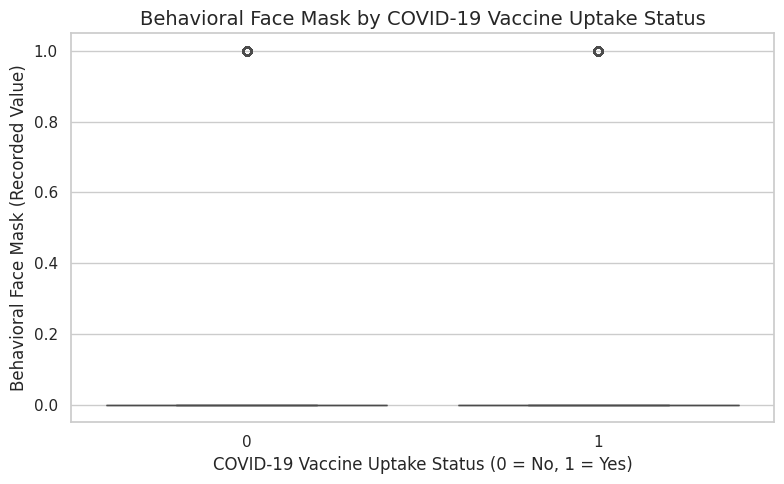

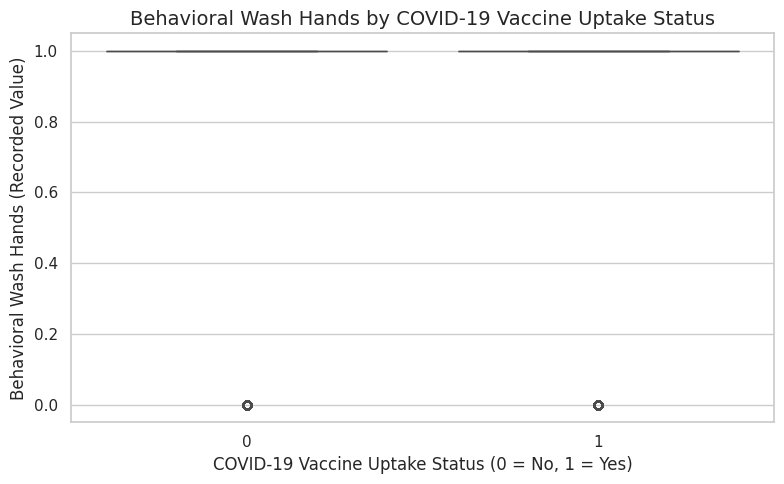

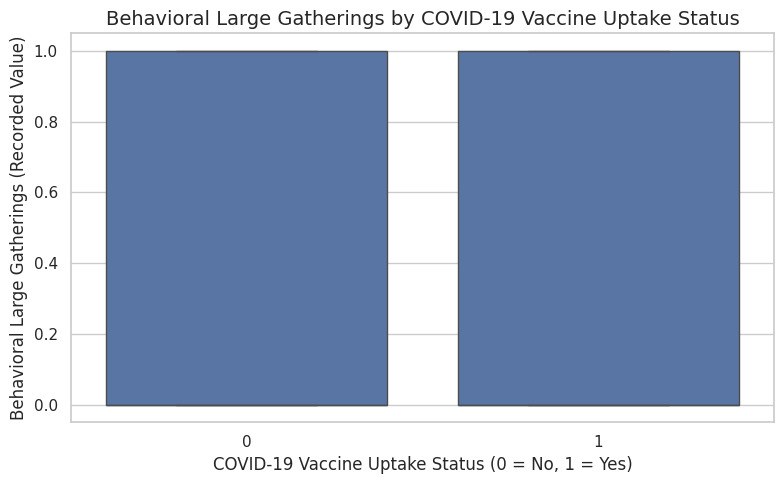

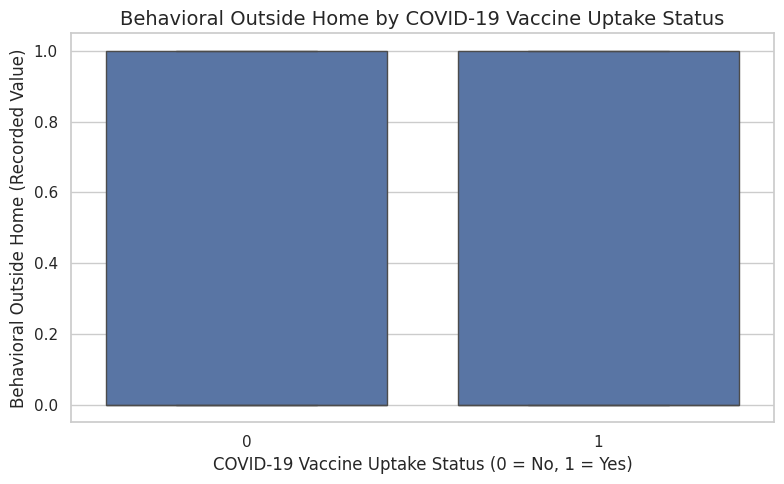

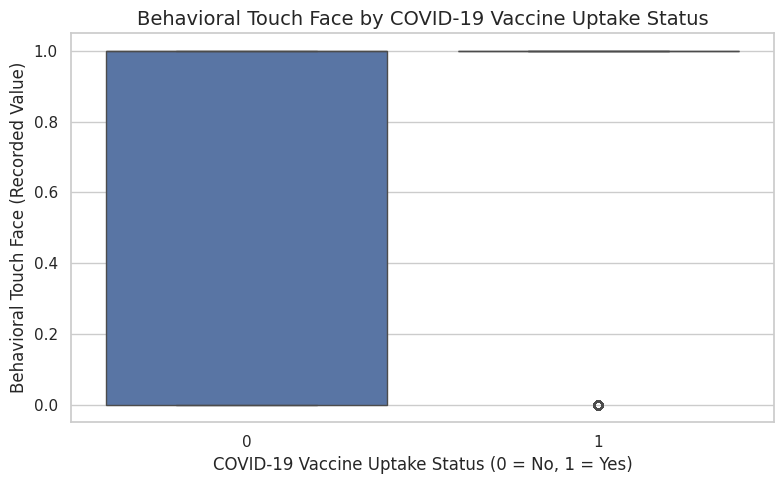

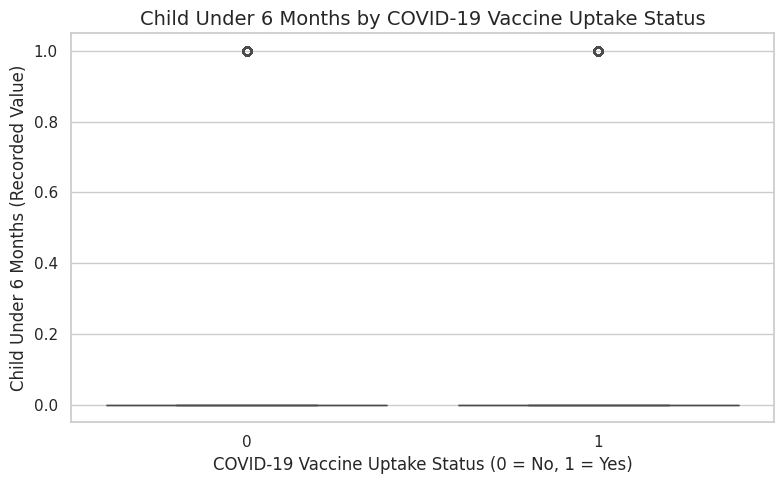

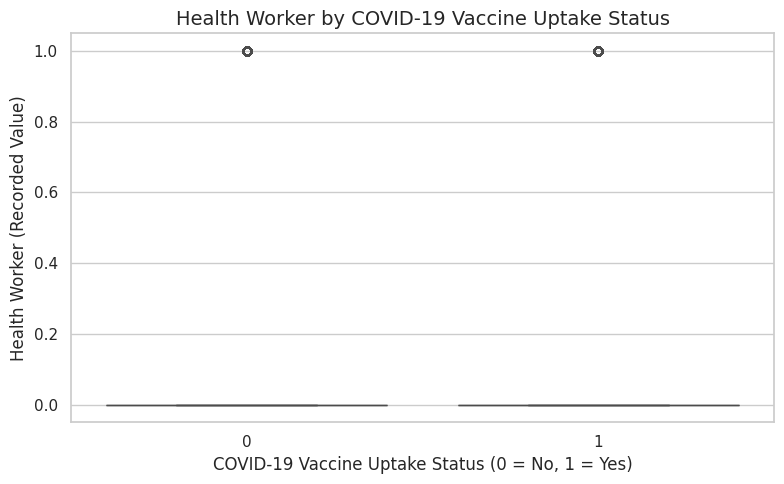

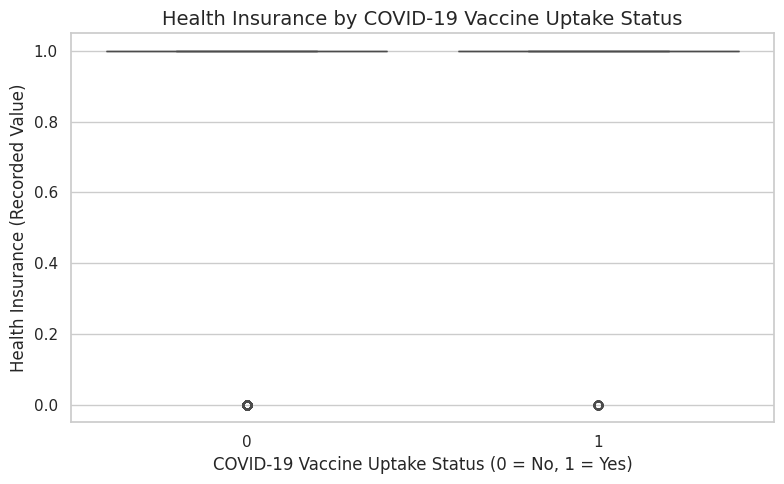

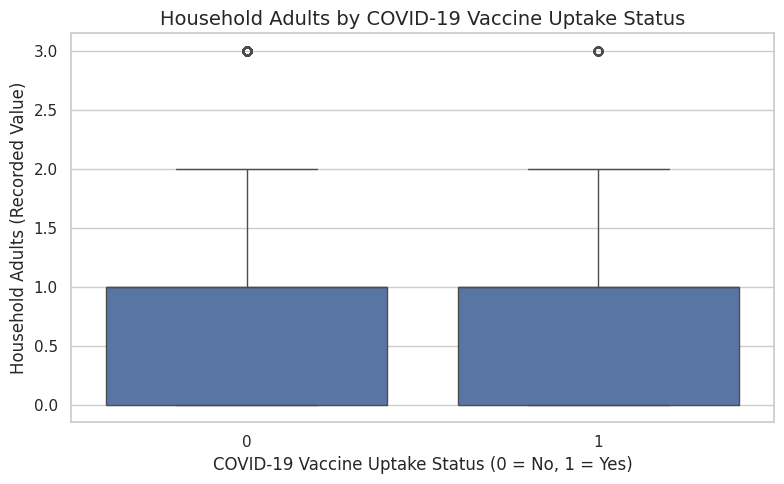

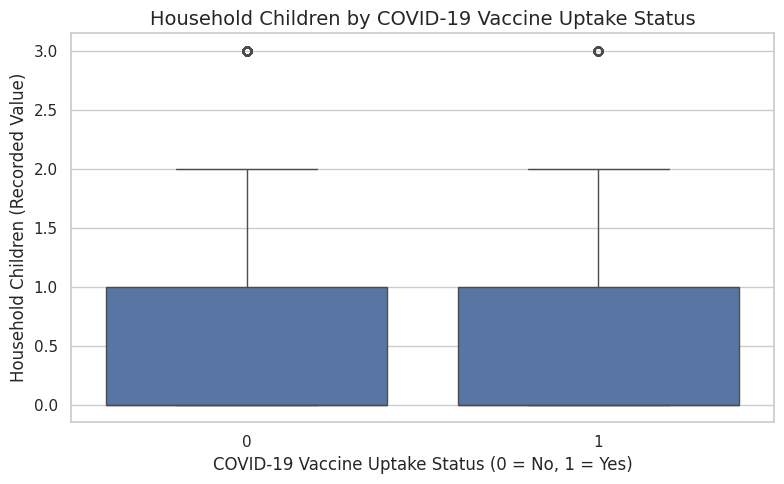

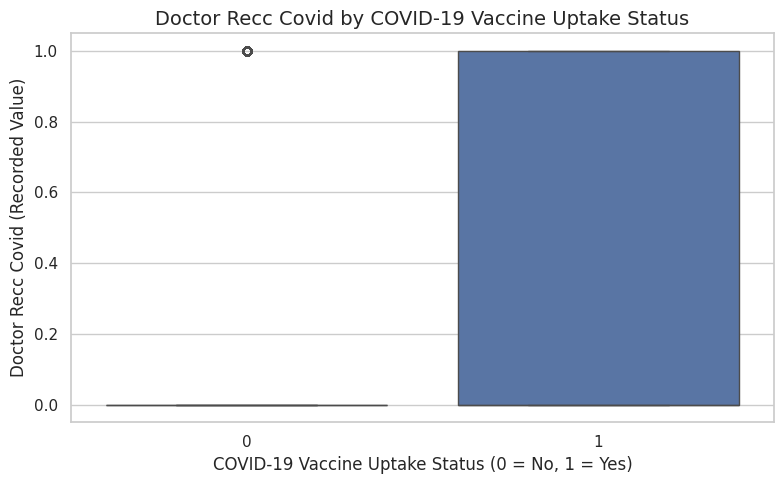

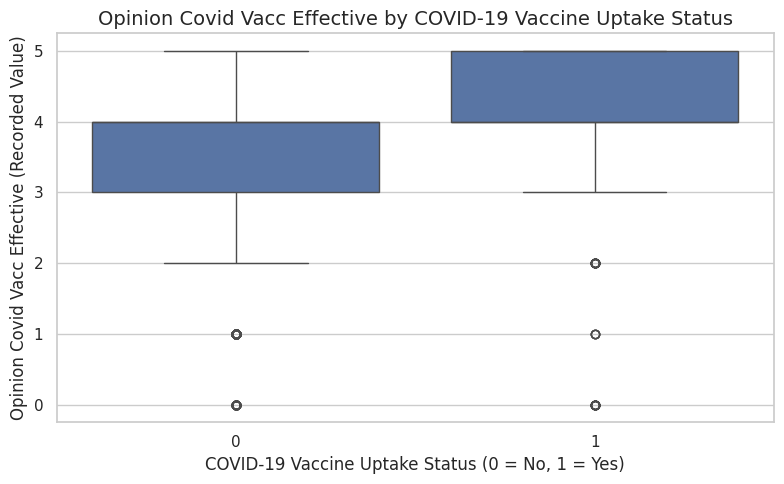

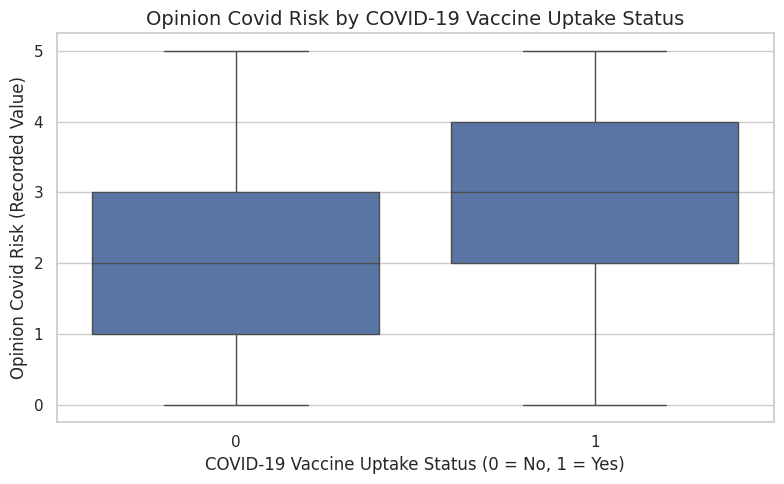

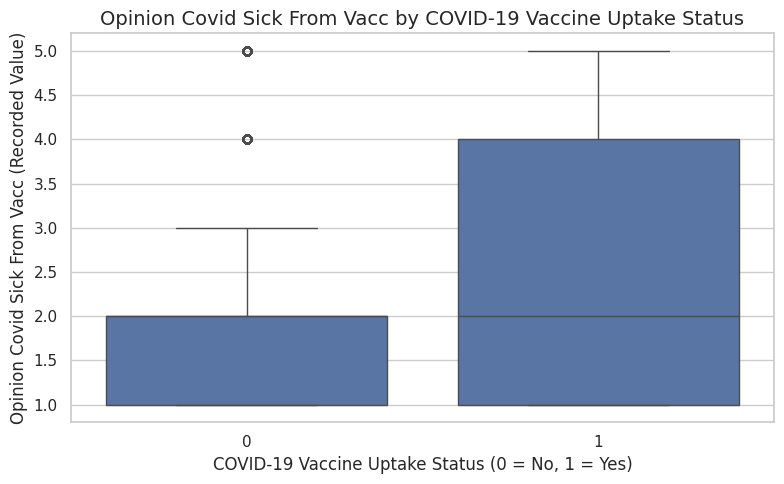

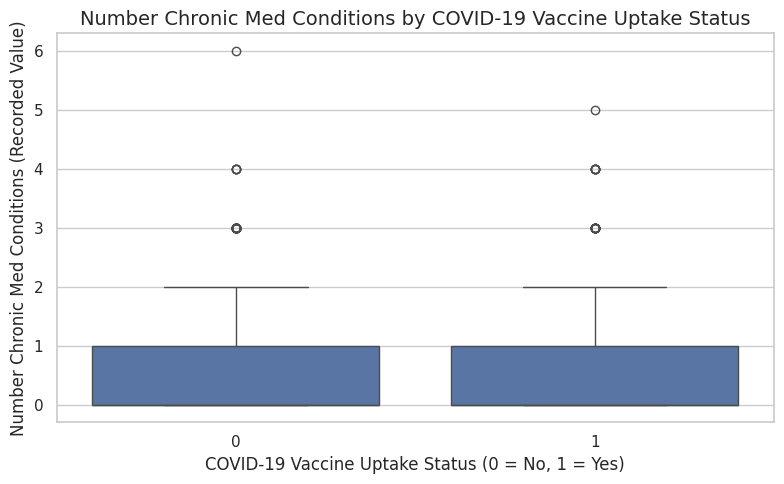

In [ ]:

for col in numeric_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=train,
        x="covid_vaccine",
        y=col
    )

    plt.title(
        f"{col.replace('_', ' ').title()} by COVID-19 Vaccine Uptake Status",
        fontsize=14
    )

    plt.xlabel(
        "COVID-19 Vaccine Uptake Status (0 = No, 1 = Yes)"
    )

    plt.ylabel(
        f"{col.replace('_', ' ').title()} (Recorded Value)"
    )

    plt.tight_layout()
    plt.show()


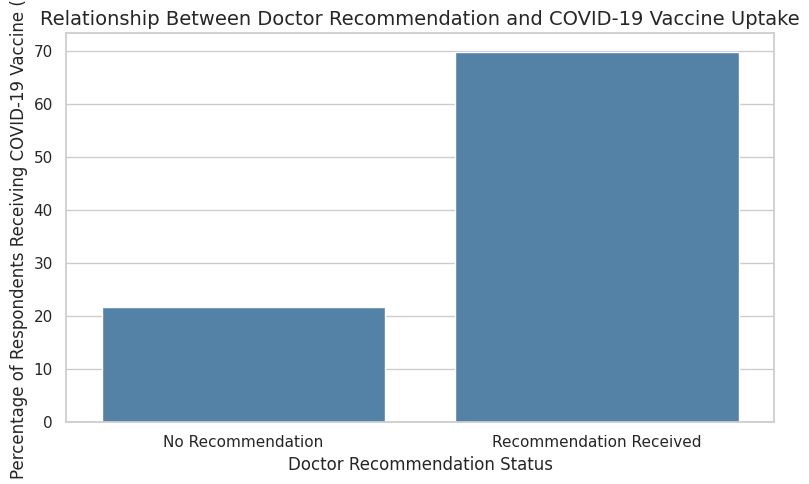

In [ ]:

doctor_data = (
    train.groupby("doctor_recc_covid")["covid_vaccine"]
    .mean()
    .mul(100)
    .reset_index()
)

doctor_data["Recommendation"] = doctor_data[
    "doctor_recc_covid"
].map({
    0: "No Recommendation",
    1: "Recommendation Received"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=doctor_data,
    x="Recommendation",
    y="covid_vaccine",
    color="steelblue"
)

plt.title(
    "Relationship Between Doctor Recommendation and COVID-19 Vaccine Uptake",
    fontsize=14
)

plt.xlabel(
    "Doctor Recommendation Status"
)

plt.ylabel(
    "Percentage of Respondents Receiving COVID-19 Vaccine (%)"
)

plt.tight_layout()
plt.show()


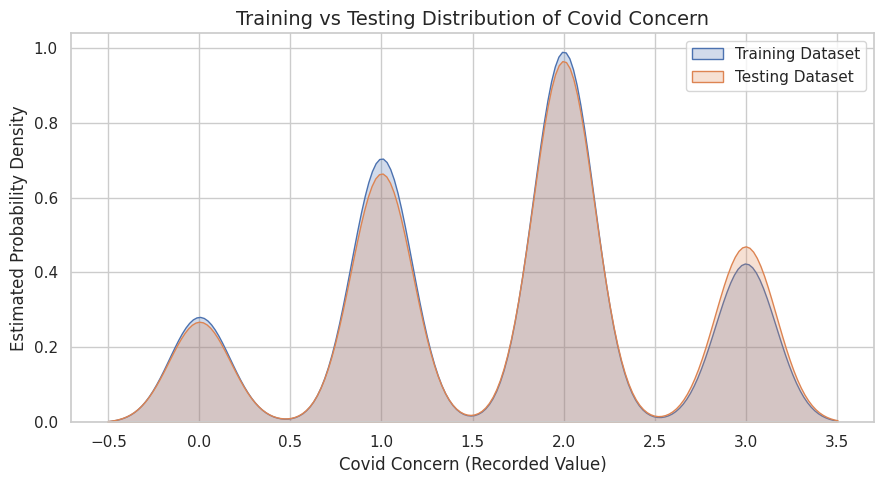

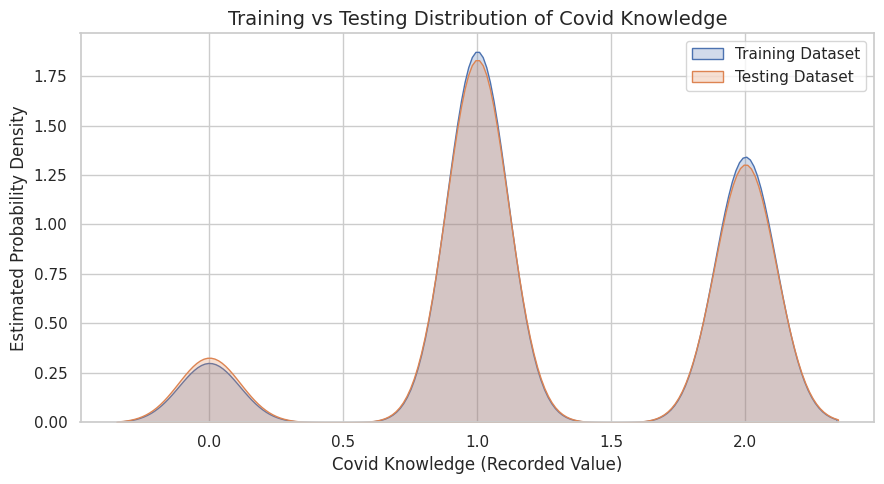

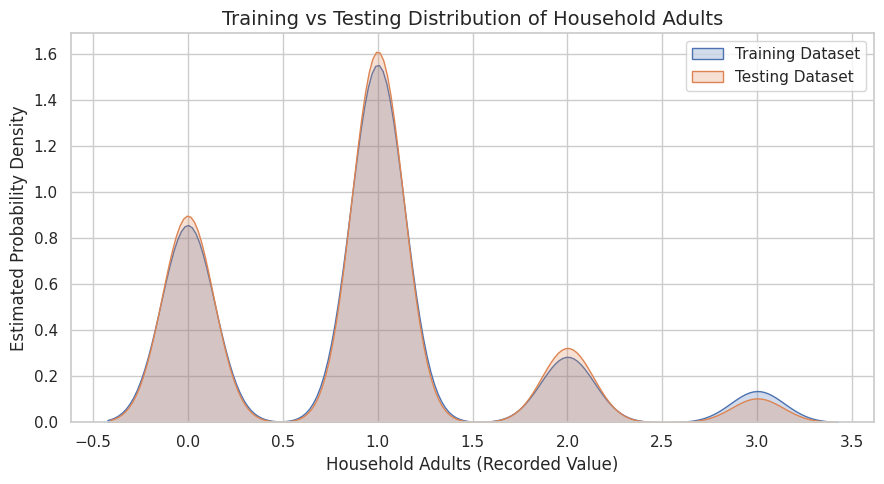

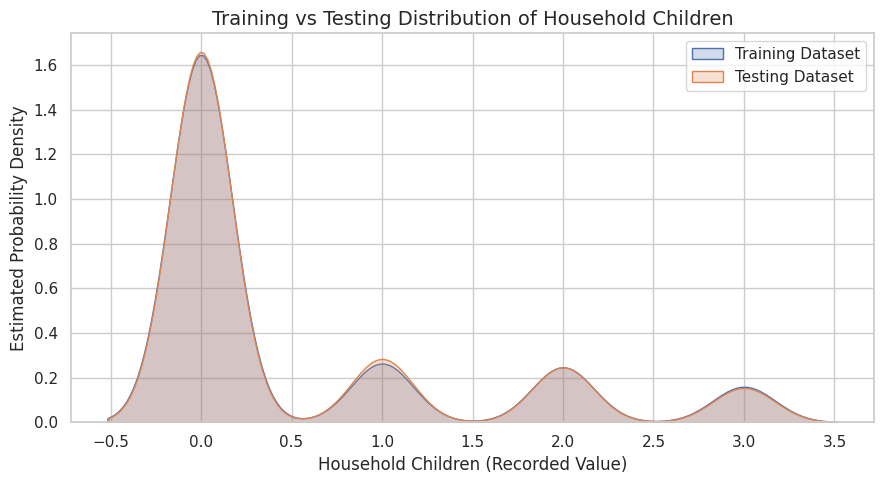

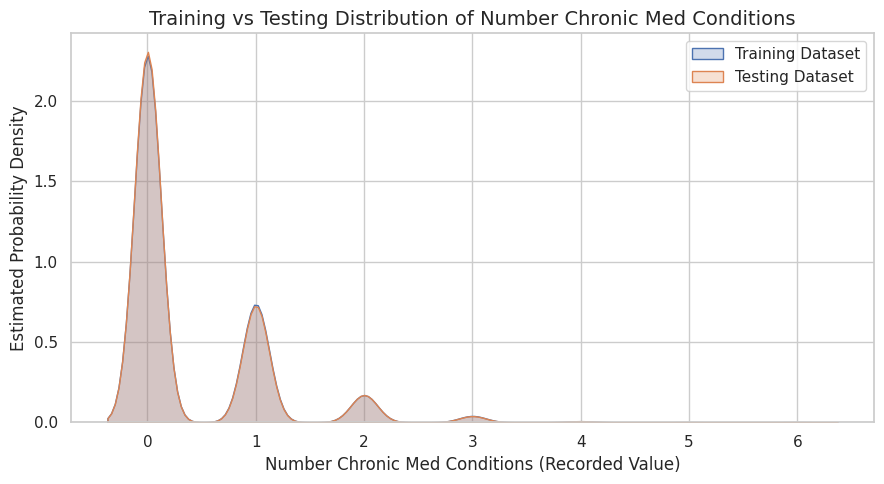

In [ ]:

comparison_features = [
    "covid_concern",
    "covid_knowledge",
    "household_adults",
    "household_children",
    "number_chronic_med_conditions"
]

for col in comparison_features:

    plt.figure(figsize=(9, 5))

    sns.kdeplot(
        data=train,
        x=col,
        label="Training Dataset",
        fill=True,
        alpha=0.25
    )

    sns.kdeplot(
        data=test,
        x=col,
        label="Testing Dataset",
        fill=True,
        alpha=0.25
    )

    plt.title(
        f"Training vs Testing Distribution of {col.replace('_', ' ').title()}",
        fontsize=14
    )

    plt.xlabel(
        f"{col.replace('_', ' ').title()} (Recorded Value)"
    )

    plt.ylabel(
        "Estimated Probability Density"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:

TARGET = "covid_vaccine"
ID_COL = "respondent_id"

X = train.drop(
    columns=[TARGET, ID_COL]
)

y = train[TARGET]

X_test = test.drop(
    columns=[ID_COL]
)

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="__MISSING__"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))
print("Total original predictors:", X.shape[1])


Numerical features: 19
Categorical features: 10
Total original predictors: 29


In [ ]:

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Validation observations:", X_valid.shape[0])

print(
    "Training positive class percentage:",
    round(y_train.mean() * 100, 2)
)

print(
    "Validation positive class percentage:",
    round(y_valid.mean() * 100, 2)
)


Training observations: 3804
Validation observations: 952
Training positive class percentage: 32.68
Validation positive class percentage: 32.67


In [ ]:

!pip -q install xgboost lightgbm


In [ ]:

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        C=0.5,
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=220,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=5,
        reg_lambda=5,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=220,
        learning_rate=0.03,
        num_leaves=12,
        min_child_samples=40,
        reg_lambda=5,
        verbosity=-1,
        random_state=42
    )
}

print("Models prepared:", list(models.keys()))


Models prepared: ['Logistic Regression', 'Random Forest', 'Extra Trees', 'XGBoost', 'LightGBM']


In [ ]:

results = []

trained_models = {}
predicted_probabilities = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_valid)

    probabilities = pipeline.predict_proba(
        X_valid
    )[:, 1]

    trained_models[name] = pipeline
    predicted_probabilities[name] = probabilities

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_valid, predictions
        ),
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_valid, probabilities
        ),
        "Log Loss": log_loss(
            y_valid, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC-AUC",
        ascending=False
    ).round(4)
)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
3,XGBoost,0.8172,0.7729,0.6238,0.6904,0.8656,0.4219
0,Logistic Regression,0.8193,0.7643,0.6463,0.7003,0.8605,0.4279
4,LightGBM,0.8099,0.7481,0.6302,0.6841,0.8596,0.4272
1,Random Forest,0.8172,0.7175,0.7267,0.7220,0.8592,0.4700
2,Extra Trees,0.8015,0.6860,0.7235,0.7042,0.8550,0.4684


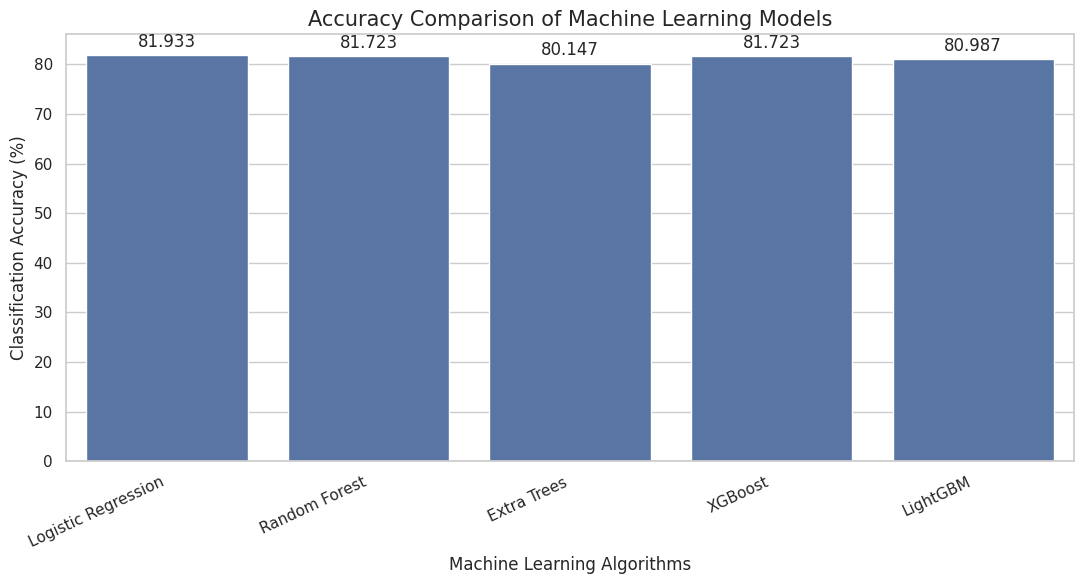

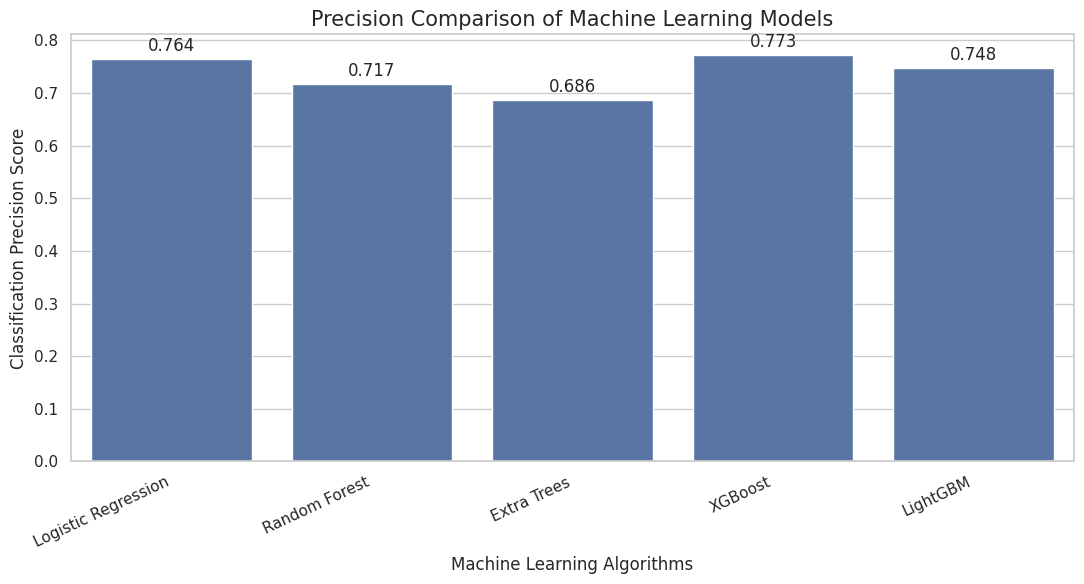

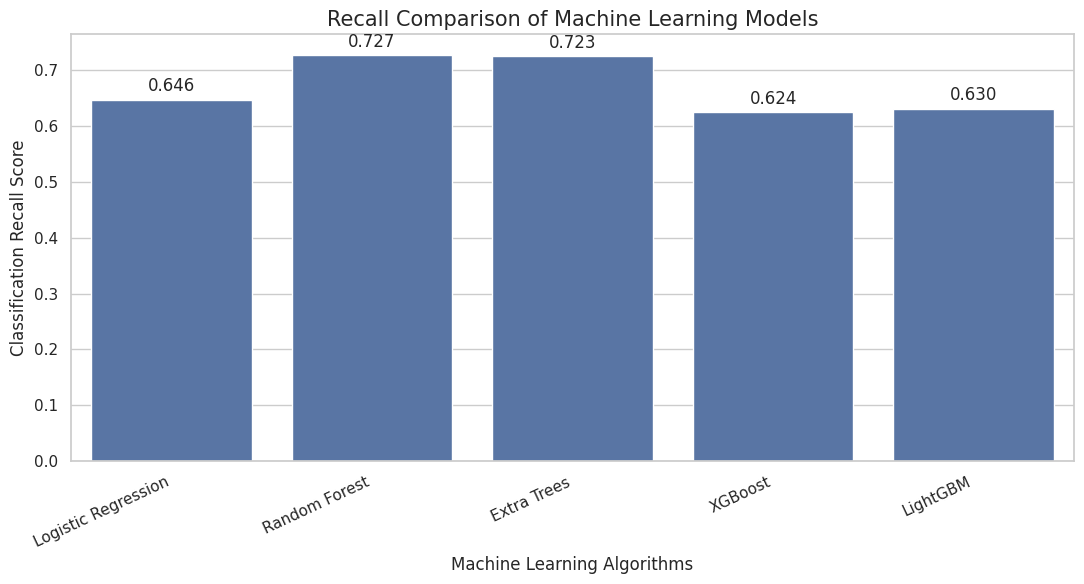

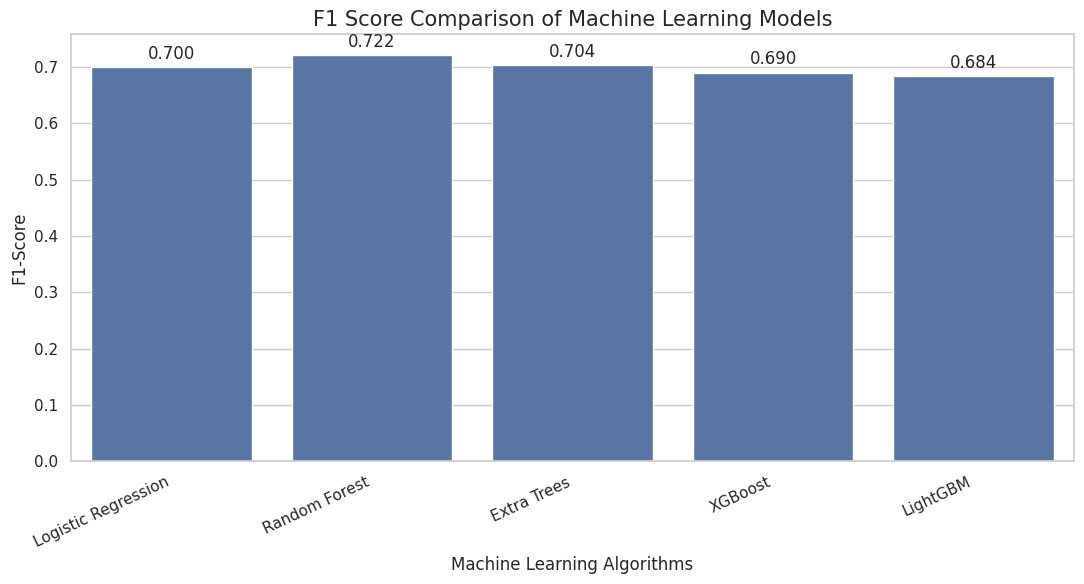

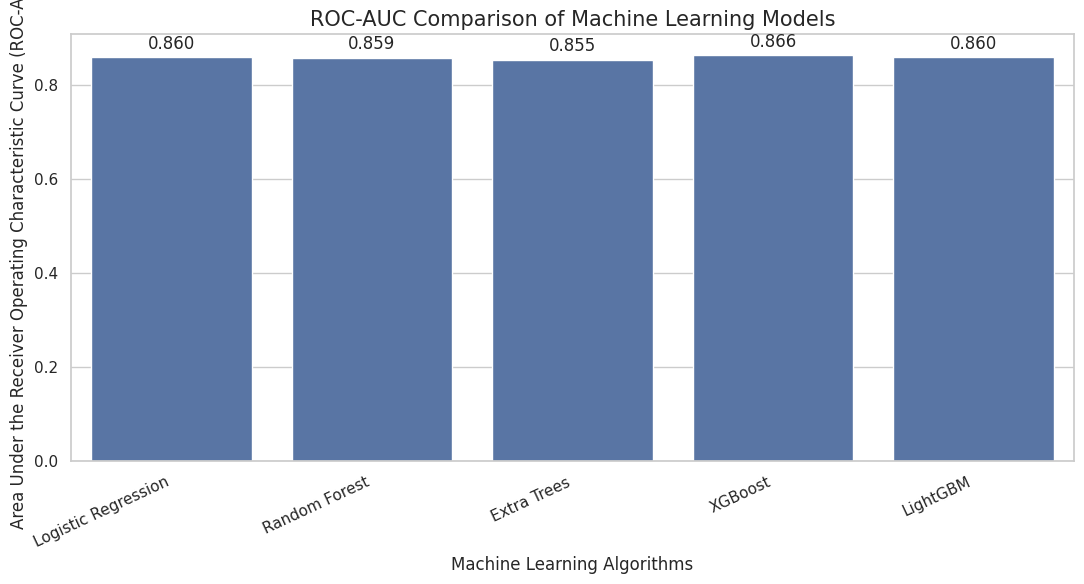

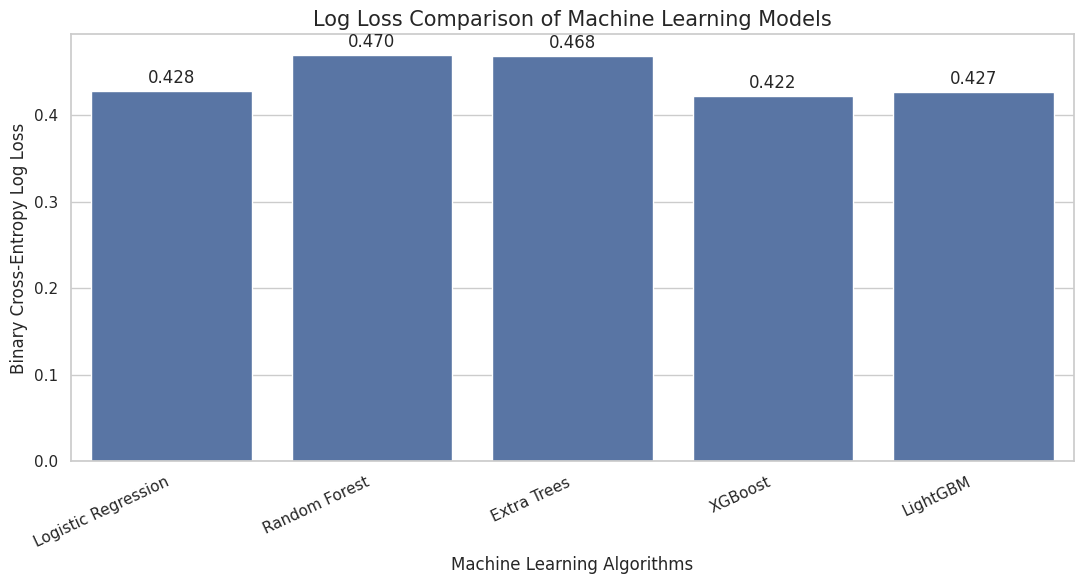

In [ ]:

metrics = [
    ("Accuracy", "Classification Accuracy (%)"),
    ("Precision", "Classification Precision Score"),
    ("Recall", "Classification Recall Score"),
    ("F1 Score", "F1-Score"),
    ("ROC-AUC", "Area Under the Receiver Operating Characteristic Curve (ROC-AUC)"),
    ("Log Loss", "Binary Cross-Entropy Log Loss")
]

for metric, y_label in metrics:

    plot_data = results_df.copy()

    if metric == "Accuracy":
        plot_data[metric] = plot_data[metric] * 100
        y_label = "Classification Accuracy (%)"

    plt.figure(figsize=(11, 6))

    ax = sns.barplot(
        data=plot_data,
        x="Model",
        y=metric
    )

    plt.title(
        f"{metric} Comparison of Machine Learning Models",
        fontsize=15
    )

    plt.xlabel("Machine Learning Algorithms")
    plt.ylabel(y_label)

    plt.xticks(rotation=25, ha="right")

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.3f",
            padding=3
        )

    plt.tight_layout()
    plt.show()


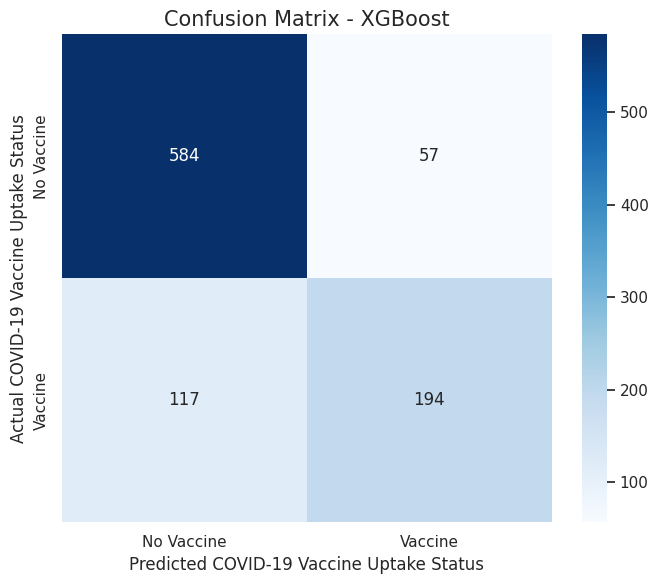

              precision    recall  f1-score   support

  No Vaccine       0.83      0.91      0.87       641
     Vaccine       0.77      0.62      0.69       311

    accuracy                           0.82       952
   macro avg       0.80      0.77      0.78       952
weighted avg       0.81      0.82      0.81       952



In [ ]:

best_model_name = results_df.sort_values(
    "ROC-AUC",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_valid)

cm = confusion_matrix(
    y_valid,
    best_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Vaccine", "Vaccine"],
    yticklabels=["No Vaccine", "Vaccine"]
)

plt.title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=15
)

plt.xlabel(
    "Predicted COVID-19 Vaccine Uptake Status"
)

plt.ylabel(
    "Actual COVID-19 Vaccine Uptake Status"
)

plt.tight_layout()
plt.show()

print(classification_report(
    y_valid,
    best_predictions,
    target_names=["No Vaccine", "Vaccine"]
))


## Added: Cost-sensitive model evaluation

The CSV files do not contain financial-cost columns, so the costs below are **assumptions
supplied by the project team**, not costs learned from the dataset. Replace the example
values with defensible values from your project brief or research.

This section estimates the cost of classification mistakes:
- False negative: the model predicts no uptake, but the person does take up the vaccine.
- False positive: the model predicts uptake, but the person does not take up the vaccine.

The cost ratio determines which mistake is considered more expensive. Do not present the
example costs as real-world facts.

In [ ]:
# EXAMPLE PLACEHOLDER COSTS — replace with values justified by your team.
# These are generic cost units, not values supplied in Dataset C.
COST_FALSE_NEGATIVE = 10.0
COST_FALSE_POSITIVE = 2.0
COST_TRUE_POSITIVE = 0.0
COST_TRUE_NEGATIVE = 0.0

# Use the validation predictions from the model selected by ROC-AUC.
validation_probabilities = best_model.predict_proba(X_valid)[:, 1]
validation_labels = (validation_probabilities >= 0.50).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_valid, validation_labels, labels=[0, 1]
).ravel()

validation_error_cost = (
    fn * COST_FALSE_NEGATIVE
    + fp * COST_FALSE_POSITIVE
    + tp * COST_TRUE_POSITIVE
    + tn * COST_TRUE_NEGATIVE
)

cost_summary = pd.DataFrame({
    "Measure": [
        "True negatives", "False positives", "False negatives", "True positives",
        "Total validation error cost", "Average cost per validation record"
    ],
    "Value": [
        tn, fp, fn, tp, validation_error_cost,
        validation_error_cost / len(y_valid)
    ]
})
display(cost_summary)

print(
    "Important: this is a scenario estimate based on the placeholder costs above. "
    "It is not an official competition score."
)

,Measure,Value
0,True negatives,584.000000
1,False positives,57.000000
2,False negatives,117.000000
3,True positives,194.000000
4,Total validation error cost,1284.000000
5,Average cost per validation record,1.348739


Important: this is a scenario estimate based on the placeholder costs above. It is not an official competition score.


### Added: Compare decision thresholds using the assumed error costs

ROC-AUC evaluates ranking and does not choose a decision threshold. The next cell checks
thresholds from 0.05 to 0.95 and finds the threshold with the lowest **assumed** validation
error cost. This threshold should only be used if the cost assumptions are appropriate
for the actual decision being modelled.

In [ ]:
threshold_rows = []

for threshold in np.arange(0.05, 1.00, 0.05):
    labels_at_threshold = (validation_probabilities >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        y_valid, labels_at_threshold, labels=[0, 1]
    ).ravel()

    total_cost = (
        fn_t * COST_FALSE_NEGATIVE
        + fp_t * COST_FALSE_POSITIVE
        + tp_t * COST_TRUE_POSITIVE
        + tn_t * COST_TRUE_NEGATIVE
    )

    threshold_rows.append({
        "Threshold": threshold,
        "False Positives": fp_t,
        "False Negatives": fn_t,
        "Total Assumed Cost": total_cost,
        "Cost per Record": total_cost / len(y_valid)
    })

threshold_cost_df = pd.DataFrame(threshold_rows)
display(threshold_cost_df.sort_values("Total Assumed Cost").head(10))

best_cost_threshold = threshold_cost_df.loc[
    threshold_cost_df["Total Assumed Cost"].idxmin(), "Threshold"
]
print("Lowest-cost threshold under the current assumptions:", best_cost_threshold)

,Threshold,False Positives,False Negatives,Total Assumed Cost,Cost per Record
3,0.20,234,36,828.0,0.869748
2,0.15,307,24,854.0,0.897059
4,0.25,187,50,874.0,0.918067
5,0.30,146,60,892.0,0.936975
6,0.35,114,74,968.0,1.016807
1,0.10,431,12,982.0,1.031513
7,0.40,88,90,1076.0,1.130252
8,0.45,69,99,1128.0,1.184874
0,0.05,593,1,1196.0,1.256303
9,0.50,57,117,1284.0,1.348739


Lowest-cost threshold under the current assumptions: 0.2


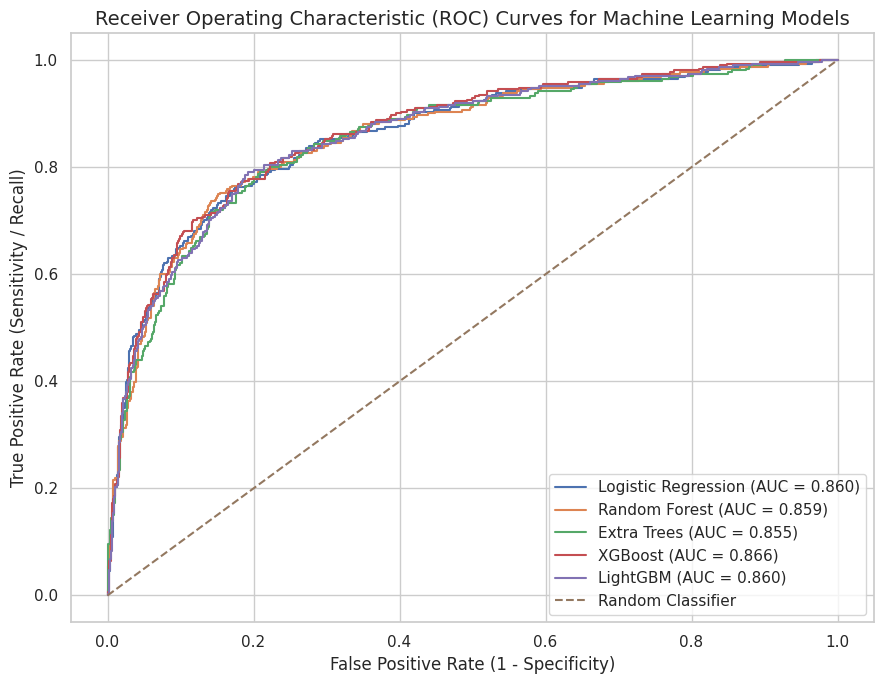

In [ ]:

plt.figure(figsize=(9, 7))

for name, probabilities in predicted_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_valid,
        probabilities
    )

    auc = roc_auc_score(
        y_valid,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "Receiver Operating Characteristic (ROC) Curves for Machine Learning Models",
    fontsize=14
)

plt.xlabel(
    "False Positive Rate (1 - Specificity)"
)

plt.ylabel(
    "True Positive Rate (Sensitivity / Recall)"
)

plt.legend()
plt.tight_layout()
plt.show()


## Added: Precision–recall curve

ROC-AUC is useful for ranking, but a precision–recall curve makes the trade-off between
finding likely vaccine recipients and avoiding false alarms easier to inspect, especially
when the target classes are not perfectly balanced.

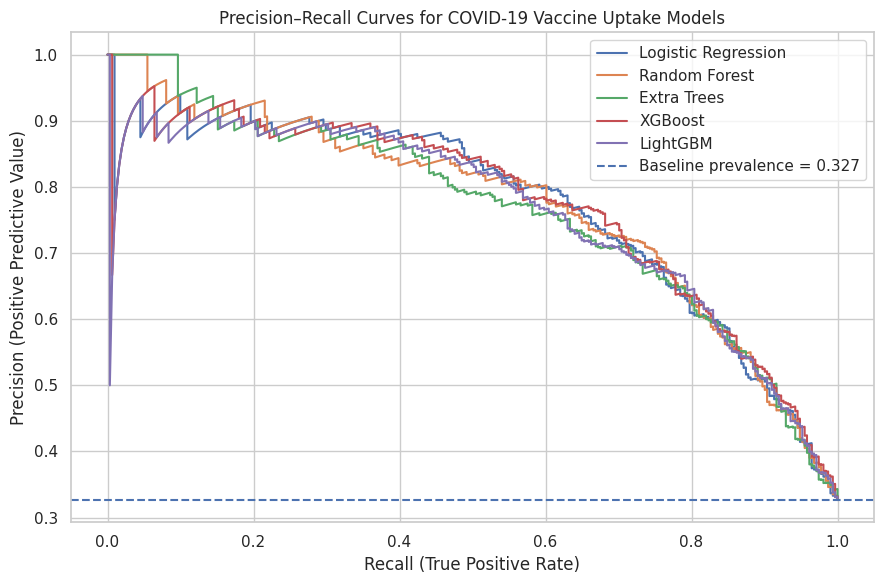

In [ ]:
plt.figure(figsize=(9, 6))

for name, probabilities in predicted_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_valid, probabilities)
    plt.plot(recall, precision, label=name)

baseline_precision = y_valid.mean()
plt.axhline(
    baseline_precision,
    linestyle="--",
    label=f"Baseline prevalence = {baseline_precision:.3f}"
)

plt.title("Precision–Recall Curves for COVID-19 Vaccine Uptake Models")
plt.xlabel("Recall (True Positive Rate)")
plt.ylabel("Precision (Positive Predictive Value)")
plt.legend()
plt.tight_layout()
plt.show()

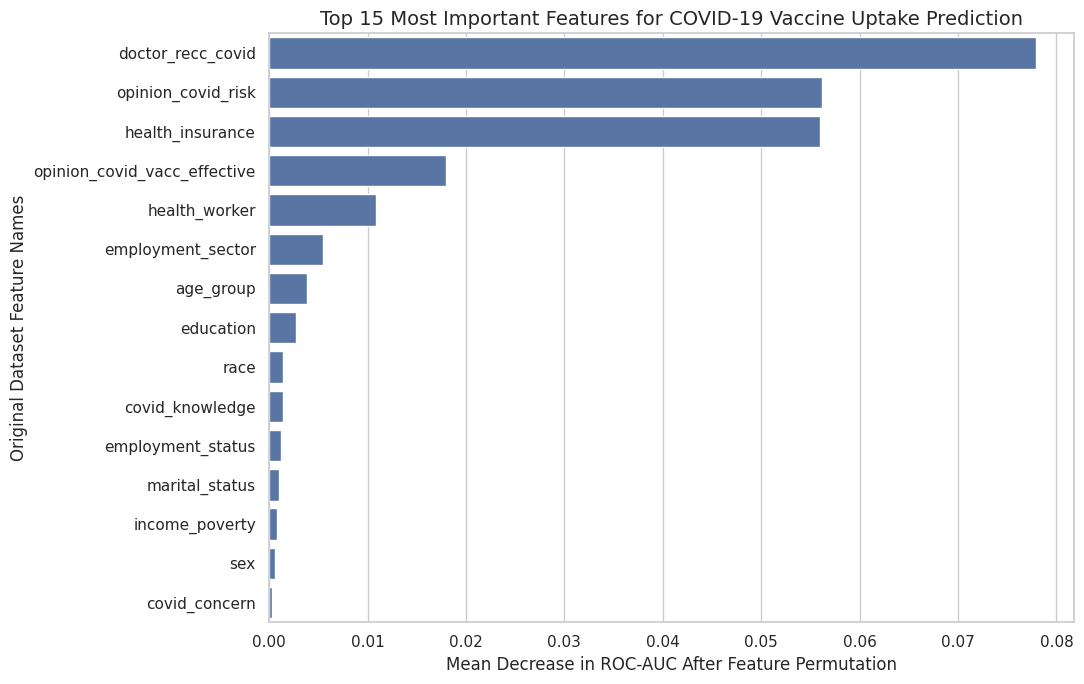

,Feature,Importance
23,doctor_recc_covid,0.077891
25,opinion_covid_risk,0.056164
11,health_insurance,0.055975
24,opinion_covid_vacc_effective,0.017974
10,health_worker,0.010840
27,employment_sector,0.005524
12,age_group,0.003835
13,education,0.002712
14,race,0.001458
1,covid_knowledge,0.001406


In [ ]:

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_result.importances_mean
}).sort_values(
    "Importance",
    ascending=False
).head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Most Important Features for COVID-19 Vaccine Uptake Prediction",
    fontsize=14
)

plt.xlabel(
    "Mean Decrease in ROC-AUC After Feature Permutation"
)

plt.ylabel(
    "Original Dataset Feature Names"
)

plt.tight_layout()
plt.show()

display(importance_df)


In [ ]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "accuracy": "accuracy",
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "neg_log_loss": "neg_log_loss"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Standard Deviation": scores["test_roc_auc"].std(),
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean F1 Score": scores["test_f1"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean Log Loss": -scores["test_neg_log_loss"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean ROC-AUC",
    ascending=False
)

display(cv_results_df.round(4))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,Mean ROC-AUC,ROC-AUC Standard Deviation,Mean Accuracy,Mean F1 Score,Mean Precision,Mean Recall,Mean Log Loss
3,XGBoost,0.8642,0.0062,0.8156,0.6897,0.7670,0.6274,0.4219
1,Random Forest,0.8641,0.0077,0.8093,0.7070,0.7119,0.7034,0.4644
0,Logistic Regression,0.8621,0.0090,0.8143,0.6899,0.7613,0.6313,0.4271
4,LightGBM,0.8615,0.0080,0.8135,0.6922,0.7522,0.6422,0.4237
2,Extra Trees,0.8584,0.0086,0.8026,0.6984,0.6992,0.6988,0.4614


## Added: Hyperparameter tuning for XGBoost

The baseline notebook compares five models but does not tune their hyperparameters. This
cell uses randomized search with stratified five-fold cross-validation and ROC-AUC. It may
take several minutes. Run it after the baseline cross-validation section.

The preprocessing remains inside the pipeline, so imputing, scaling, and encoding are
fitted separately within each cross-validation fold.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

xgb_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=2
    ))
])

xgb_param_distributions = {
    "model__n_estimators": randint(150, 501),
    "model__max_depth": randint(2, 7),
    "model__learning_rate": uniform(0.01, 0.09),
    "model__subsample": uniform(0.65, 0.35),
    "model__colsample_bytree": uniform(0.65, 0.35),
    "model__min_child_weight": randint(1, 10),
    "model__reg_lambda": uniform(1.0, 9.0)
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train, y_train)

tuned_xgb = xgb_search.best_estimator_
print("Best CV ROC-AUC:", round(xgb_search.best_score_, 4))
print("Best parameters:")
display(pd.Series(xgb_search.best_params_, name="Best value").to_frame())

tuned_valid_probabilities = tuned_xgb.predict_proba(X_valid)[:, 1]
print(
    "Tuned XGBoost holdout ROC-AUC:",
    round(roc_auc_score(y_valid, tuned_valid_probabilities), 4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV ROC-AUC: 0.8654
Best parameters:


,Best value
model__colsample_bytree,0.692731
model__learning_rate,0.042067
model__max_depth,2.000000
model__min_child_weight,1.000000
model__n_estimators,432.000000
model__reg_lambda,4.843970
model__subsample,0.936305


Tuned XGBoost holdout ROC-AUC: 0.8667


## Added: Explainable AI with SHAP

Permutation importance already exists in the original notebook. SHAP adds both a global
view of feature influence and a view of how feature values move predictions. This uses
the tuned XGBoost model and a manageable sample of validation records.

If SHAP is not installed in the runtime, install it first using the next cell.

In [ ]:
!pip -q install shap

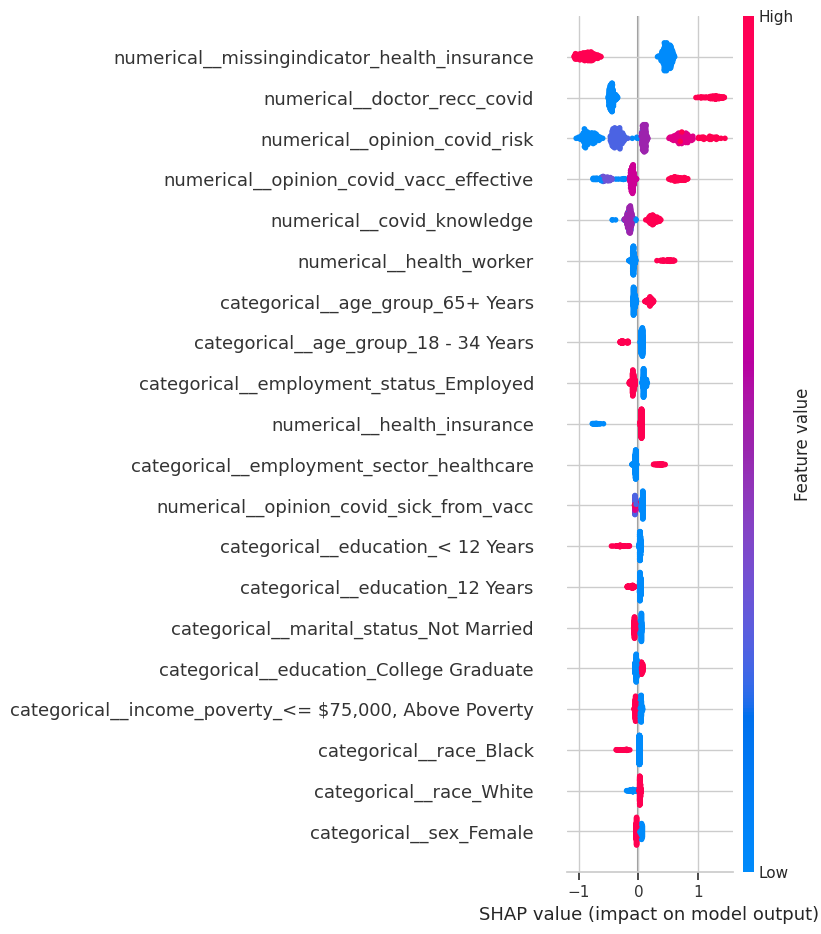

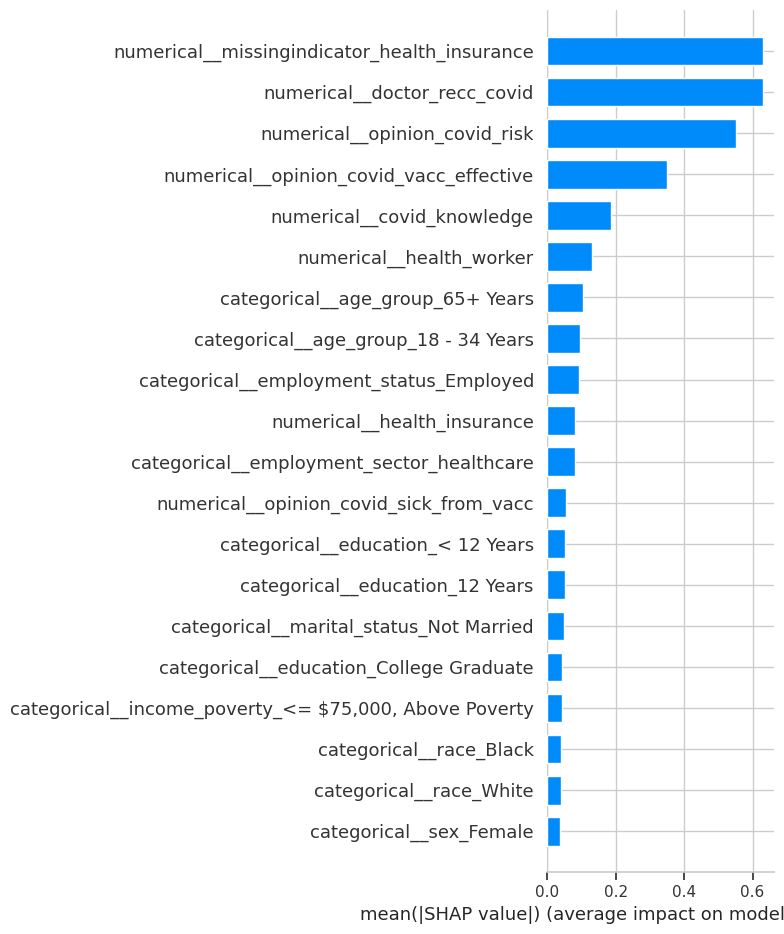

In [ ]:
import shap

# Transform the validation data using the fitted preprocessing pipeline.
fitted_preprocessor = tuned_xgb.named_steps["preprocessing"]
fitted_xgb_model = tuned_xgb.named_steps["model"]

X_valid_transformed = fitted_preprocessor.transform(X_valid)
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

# Sample up to 500 rows to keep SHAP computation practical.
sample_size = min(500, X_valid_transformed.shape[0])
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(
    X_valid_transformed.shape[0],
    size=sample_size,
    replace=False
)
X_shap = X_valid_transformed[sample_indices]
if hasattr(X_shap, 'toarray'):
    X_shap = X_shap.toarray()

explainer = shap.TreeExplainer(fitted_xgb_model)
shap_values = explainer.shap_values(X_shap)

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=transformed_feature_names,
    show=True
)

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=transformed_feature_names,
    plot_type="bar",
    show=True
)

## Final: Five model submissions and operational cost comparison

This is the only final export and operational-cost section. It ranks the five models by cross-validation ROC-AUC, fits each model on all labelled training records, and creates exactly one probability-submission CSV per model. It also estimates an illustrative outreach programme cost for each model.

**Important:** the target population, outreach cost, vaccine administration cost, and uptake improvement below are scenario assumptions. Replace them with values supported by your project research. The test set has no known target labels, so this is a planning estimate, not a measured programme cost. Check the competition instructions to confirm whether it expects probabilities or 0/1 labels.

In [ ]:
# ============================================================
# FINAL EXPORT: EXACTLY FIVE MODEL CSV FILES + COST COMPARISON
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# 1. EDITABLE OPERATIONAL COST ASSUMPTIONS
# ------------------------------------------------------------

CURRENCY = "USD"  # Change to GBP if your project uses pounds.

OUTREACH_COST_PER_PERSON = 2.00
VACCINE_ADMIN_COST_PER_DOSE = 15.00
ASSUMED_ABSOLUTE_UPTAKE_LIFT = 0.05
LOW_UPTAKE_PROBABILITY_CUTOFF = 0.50

# Illustrative only: replace with the population your group is studying.
TARGET_POPULATION = 10_000_000

# Probability is used in the CSV because it preserves model confidence.
# Change this only if the competition explicitly requires 0/1 labels.
SUBMISSION_USES_PROBABILITIES = True

# ------------------------------------------------------------
# 2. CHECK REQUIRED OBJECTS AND COLUMNS
# ------------------------------------------------------------

required_objects = [
    "X", "y", "X_test", "test", "models",
    "preprocessor", "cv_results_df"
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(
        "Run the earlier notebook cells first. Missing: "
        + ", ".join(missing_objects)
    )

TARGET = "covid_vaccine"
ID_COL = "respondent_id"

if ID_COL not in test.columns:
    raise KeyError(f"Testing data must contain '{ID_COL}'.")
if "Model" not in cv_results_df.columns or "Mean ROC-AUC" not in cv_results_df.columns:
    raise KeyError("Cross-validation results must contain Model and Mean ROC-AUC.")

if TARGET_POPULATION <= 0:
    raise ValueError("TARGET_POPULATION must be greater than zero.")
if not 0 <= ASSUMED_ABSOLUTE_UPTAKE_LIFT <= 1:
    raise ValueError("ASSUMED_ABSOLUTE_UPTAKE_LIFT must be between 0 and 1.")

# ------------------------------------------------------------
# 3. SELECT THE FIVE BEST MODELS BY CV ROC-AUC
# ------------------------------------------------------------

top_models = (
    cv_results_df
    .dropna(subset=["Mean ROC-AUC"])
    .sort_values("Mean ROC-AUC", ascending=False)
    ["Model"]
    .head(5)
    .tolist()
)

if len(top_models) != 5:
    raise ValueError(
        f"Expected five models in cross-validation results; found {len(top_models)}."
    )

print("Models ranked by mean cross-validation ROC-AUC:")
display(
    cv_results_df[cv_results_df["Model"].isin(top_models)]
    .sort_values("Mean ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. CREATE A CLEAN OUTPUT FOLDER
# ------------------------------------------------------------

OUTPUT_DIR = "submissions"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Remove only CSV files created by this final submission section.
# This prevents old duplicate probability/label files from remaining.
for old_file in glob.glob(os.path.join(OUTPUT_DIR, "submission_*.csv")):
    os.remove(old_file)

cost_rows = []
submission_rows = []

# ------------------------------------------------------------
# 5. FIT EACH MODEL, CREATE ITS CSV, AND ESTIMATE ITS COST
# ------------------------------------------------------------

for rank, model_name in enumerate(top_models, start=1):

    print(f"\nTraining model {rank}/5: {model_name}")

    final_pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", models[model_name])
    ])

    # Fit on all labelled training observations.
    final_pipeline.fit(X, y)

    # Predicted probability of vaccine uptake (class 1).
    probabilities = final_pipeline.predict_proba(X_test)[:, 1]

    # Binary classification at 0.50, for reporting only.
    predicted_labels = (probabilities >= 0.50).astype(int)

    # --------------------------------------------------------
    # 5A. SAVE ONE CSV FOR THIS MODEL
    # --------------------------------------------------------

    if SUBMISSION_USES_PROBABILITIES:
        submission_values = probabilities
    else:
        submission_values = predicted_labels

    submission_df = pd.DataFrame({
        ID_COL: test[ID_COL].to_numpy(),
        TARGET: submission_values
    })

    safe_model_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("/", "_")
    )
    csv_path = os.path.join(
        OUTPUT_DIR,
        f"submission_{rank}_{safe_model_name}.csv"
    )
    submission_df.to_csv(csv_path, index=False)

    submission_rows.append({
        "Rank": rank,
        "Model": model_name,
        "Mean CV ROC-AUC": float(
            cv_results_df.loc[
                cv_results_df["Model"] == model_name,
                "Mean ROC-AUC"
            ].iloc[0]
        ),
        "CSV File": csv_path,
        "Test Rows": len(submission_df),
        "Mean Predicted Uptake Probability": float(probabilities.mean()),
        "Predicted Uptake at 0.50 (%)": float(predicted_labels.mean() * 100)
    })

    # --------------------------------------------------------
    # 5B. MODEL-SPECIFIC OUTREACH COST SCENARIO
    # --------------------------------------------------------

    # Select records whose predicted probability of uptake is below
    # the outreach cutoff.
    selected_mask = probabilities < LOW_UPTAKE_PROBABILITY_CUTOFF

    test_population = len(probabilities)
    selected_in_test = int(selected_mask.sum())

    # Scale the selected share in the test sample to the assumed
    # target population. This assumes the test sample represents
    # the target population; validate this assumption before reporting.
    outreach_rate = (
        selected_in_test / test_population if test_population else 0.0
    )
    estimated_outreach_population = outreach_rate * TARGET_POPULATION

    # Additional vaccinations are a scenario based on the assumed
    # absolute uptake lift among people reached.
    estimated_additional_vaccinations = (
        estimated_outreach_population * ASSUMED_ABSOLUTE_UPTAKE_LIFT
    )

    outreach_cost = (
        estimated_outreach_population * OUTREACH_COST_PER_PERSON
    )
    administration_cost = (
        estimated_additional_vaccinations * VACCINE_ADMIN_COST_PER_DOSE
    )
    total_estimated_cost = outreach_cost + administration_cost

    cost_rows.append({
        "Rank": rank,
        "Model": model_name,
        "Mean CV ROC-AUC": float(
            cv_results_df.loc[
                cv_results_df["Model"] == model_name,
                "Mean ROC-AUC"
            ].iloc[0]
        ),
        "Test Population": test_population,
        "People Selected in Test": selected_in_test,
        "Outreach Rate (%)": outreach_rate * 100,
        "Assumed Target Population": TARGET_POPULATION,
        "Estimated People Contacted": estimated_outreach_population,
        "Assumed Uptake Lift (%)": ASSUMED_ABSOLUTE_UPTAKE_LIFT * 100,
        "Estimated Additional Vaccinations": estimated_additional_vaccinations,
        "Outreach Cost": outreach_cost,
        "Vaccine Administration Cost": administration_cost,
        "Total Estimated Cost": total_estimated_cost,
        "Cost per Additional Vaccination": (
            total_estimated_cost / estimated_additional_vaccinations
            if estimated_additional_vaccinations > 0 else np.nan
        )
    })

# ------------------------------------------------------------
# 6. DISPLAY THE FIVE CSV FILES
# ------------------------------------------------------------

submission_summary_df = pd.DataFrame(submission_rows)

print("\n========== FIVE MODEL SUBMISSION FILES ==========")
display(submission_summary_df)

created_files = sorted(
    glob.glob(os.path.join(OUTPUT_DIR, "submission_*.csv"))
)

print(f"Number of model submission CSV files created: {len(created_files)}")
for file_path in created_files:
    print(file_path)

if len(created_files) != 5:
    raise RuntimeError(
        f"Expected exactly 5 model CSV files, but found {len(created_files)}."
    )

# ------------------------------------------------------------
# 7. DISPLAY TOTAL COST ESTIMATE FOR EACH MODEL
# ------------------------------------------------------------

cost_comparison_df = pd.DataFrame(cost_rows)

money_columns = [
    "Outreach Cost",
    "Vaccine Administration Cost",
    "Total Estimated Cost",
    "Cost per Additional Vaccination"
]

print("\n========== COST ESTIMATION FOR EACH MODEL ==========")
print("Currency:", CURRENCY)
display(cost_comparison_df.round(2))

print("\n========== OVERALL COST SUMMARY ==========")
print(
    "Average estimated cost across the five models:",
    f"{CURRENCY} {cost_comparison_df['Total Estimated Cost'].mean():,.2f}"
)
print(
    "Lowest estimated model cost:",
    f"{CURRENCY} {cost_comparison_df['Total Estimated Cost'].min():,.2f}"
)
print(
    "Highest estimated model cost:",
    f"{CURRENCY} {cost_comparison_df['Total Estimated Cost'].max():,.2f}"
)

# The cost comparison is displayed in the notebook and is NOT saved
# as a sixth CSV, so the submissions folder contains exactly five
# model prediction CSV files.
print(
    "\nNote: costs are illustrative planning estimates. "
    "They are not actual costs observed in Dataset C."
)


# ------------------------------------------------------------
# 8. SHOW DIRECT DOWNLOAD LINKS FOR ALL FIVE CSV FILES
# ------------------------------------------------------------

from IPython.display import display, FileLink

print("\n========== DOWNLOAD YOUR FIVE CSV FILES ==========")
for file_path in created_files:
    display(FileLink(file_path, result_html_prefix="Download: "))


Models ranked by mean cross-validation ROC-AUC:


,Model,Mean ROC-AUC,ROC-AUC Standard Deviation,Mean Accuracy,Mean F1 Score,Mean Precision,Mean Recall,Mean Log Loss
0,XGBoost,0.864209,0.006218,0.815603,0.689734,0.766987,0.627427,0.421890
1,Random Forest,0.864078,0.007674,0.809293,0.707007,0.711877,0.703361,0.464385
2,Logistic Regression,0.862114,0.009045,0.814342,0.689890,0.761321,0.631277,0.427134
3,LightGBM,0.861468,0.007985,0.813500,0.692242,0.752187,0.642228,0.423650
4,Extra Trees,0.858363,0.008610,0.802567,0.698408,0.699217,0.698849,0.461359



Training model 1/5: XGBoost

Training model 2/5: Random Forest

Training model 3/5: Logistic Regression

Training model 4/5: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Training model 5/5: Extra Trees

========== FIVE MODEL SUBMISSION FILES ==========


,Rank,Model,Mean CV ROC-AUC,CSV File,Test Rows,Mean Predicted Uptake Probability,Predicted Uptake at 0.50 (%)
0,1,XGBoost,0.864209,submissions/submission_1_xgboost.csv,4749,0.331077,27.121499
1,2,Random Forest,0.864078,submissions/submission_2_random_forest.csv,4749,0.417877,33.754475
2,3,Logistic Regression,0.862114,submissions/submission_3_logistic_regression.csv,4749,0.334823,28.384923
3,4,LightGBM,0.861468,submissions/submission_4_lightgbm.csv,4749,0.331107,28.574437
4,5,Extra Trees,0.858363,submissions/submission_5_extra_trees.csv,4749,0.409311,33.691303


... (4 outputs left out)

/content/submissions/submission_2_random_forest.csv

/content/submissions/submission_3_logistic_regression.csv

/content/submissions/submission_4_lightgbm.csv

/content/submissions/submission_5_extra_trees.csv